Autor:  
Manuel Eugenio Morocho Cayamcela, PhD

## Procesamiento y Transformación de Datos para Análisis de Crédito
## **Kaggle Competition**

### **1. Introducción:**

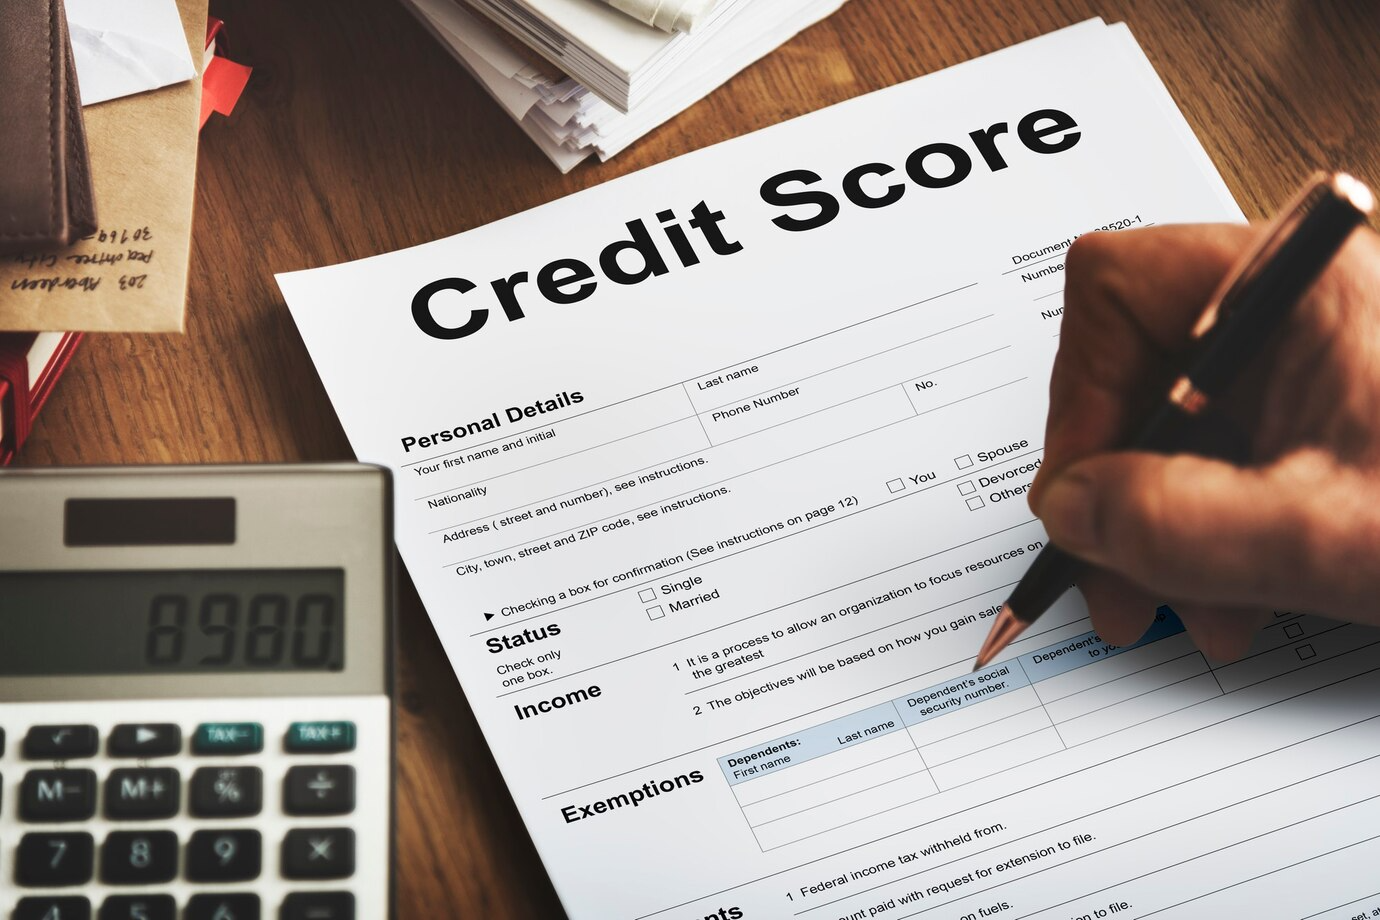

¡Bienvenidos a su primer desafío práctico en el módulo de Fundamentos de Inteligencia Artificial!

Hoy trabajarán en grupos para limpiar un dataset con errores, inconsistencias y valores faltantes. 
El objetivo es aplicar lo aprendido sobre preprocesamiento y limpieza de datos.

El modelo de clasificación ya está definido y no podrá ser modificado. La calidad de sus resultados dependerá exclusivamente de qué tan bien limpien y preparen los datos para el modelo.

Al final del día, cada grupo subirá sus predicciones a Kaggle, y la puntuación del leaderboard será parte de la calificación, junto con una rúbrica cualitativa.

Utilizaremos un conjunto de datos de solicitudes de crédito con las siguientes columnas:

1. ID: Identificador único para cada registro.
2. Customer_ID: Identificador único para cada cliente.
3. Month: Mes en el que se registró la información.
4. Name: Nombre del cliente.
5. Age: Edad del cliente.
6. SSN: Número de Seguro Social del cliente.
7. Occupation: Ocupación del cliente.
8. Annual_Income: Ingreso anual del cliente.
9. Monthly_Inhand_Salary: Salario mensual disponible del cliente.
10. Num_Bank_Accounts: Número de cuentas bancarias del cliente.
11. Num_Credit_Card: Número de tarjetas de crédito del cliente.
12. Interest_Rate: Tasa de interés aplicada al cliente.
13. Num_of_Loan: Número de préstamos del cliente.
14. Type_of_Loan: Tipo de préstamo(s) del cliente.
15. Delay_from_due_date: Retraso desde la fecha de vencimiento del pago.
16. Num_of_Delayed_Payment: Número de pagos retrasados del cliente.
17. Changed_Credit_Limit: Límite de crédito modificado del cliente.
18. Num_Credit_Inquiries: Número de consultas de crédito realizadas por el cliente.
19. Credit_Mix: Mezcla de crédito del cliente.
20. Outstanding_Debt: Deuda pendiente del cliente.
21. Credit_Utilization_Ratio: Relación de utilización de crédito del cliente.
22. Credit_History_Age: Antigüedad del historial de crédito del cliente.
23. Payment_of_Min_Amount: Pago del monto mínimo realizado por el cliente.
24. Total_EMI_per_month: Total de cuotas mensuales del cliente.
25. Amount_invested_monthly: Cantidad invertida mensualmente por el cliente.
26. Payment_Behaviour: Comportamiento de pago del cliente.
27. Monthly_Balance: Saldo mensual del cliente.
28. Credit_Score: Puntuación de crédito del cliente.

### **2. Kaggle instructions**

1. Unirse a la competencia en Kaggle.
2. Una vez dentro de la competencia, descarguen los archivos: `train.csv`, `test.csv`, y `sample_submission.csv`.
3. Realicen la limpieza del archivo `train.csv` según los pasos que consideren adecuados.
4. Entrenen el modelo provisto en este notebook (NO modificar los parámetros ni reemplazar el modelo).
5. Apliquen la limpieza equivalente al `test.csv`, generen las predicciones y súbanlas a Kaggle en formato del `sample_submission.csv`.
6. El estudiante debe documentar los pasos de limpieza aplicados en su notebook Kaggle (comentarios y celdas Markdown).

### **3. Data Cleaning**

En esta sección deben realizar las tareas de limpieza de datos necesarias:

- Imputación de valores nulos
- Eliminación o codificación de outliers
- Conversión de variables categóricas
- Escalado si es necesario
- Otras transformaciones relevantes

**IMPORTANTE:** todos estos pasos deben replicarse también en el test.csv antes de predecir.

In [ ]:
# Load the necessary libraries for data analysis and visualization
# Import the 'numpy' library with the alias 'np'
import numpy as np
# Import the 'pandas' library with the alias 'pd'
import pandas as pd
# Import the 'matplotlib.pyplot' library with the alias 'plt'
import  matplotlib.pyplot as plt
# Import the 'seaborn' library with the alias 'sns'
import seaborn as sns
# Import the 're' library for regular expressions
import re

In [ ]:
#read the dataset from the CSV file
datax = pd.read_csv('X_train_Kaggle.csv')

datay = pd.read_csv('y_train_Kaggle.csv')

data = pd.concat([datax, datay], axis=1)

dataxtest = pd.read_csv('X_test_Kaggle.csv')

C:\Users\darth\AppData\Local\Temp\ipykernel_23076\1278068590.py:2: DtypeWarning: Columns (26) have mixed types. Specify dtype option on import or set low_memory=False.
  datax = pd.read_csv('X_train_Kaggle.csv')


In [ ]:
data.shape

(70000, 28)

In [ ]:
# Check the data type of each column with the 'info()' method of the 'data' DataFrame
data.info(verbose=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 28 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID                        70000 non-null  object 
 1   Customer_ID               70000 non-null  object 
 2   Month                     70000 non-null  object 
 3   Name                      63016 non-null  object 
 4   Age                       70000 non-null  object 
 5   SSN                       70000 non-null  object 
 6   Occupation                70000 non-null  object 
 7   Annual_Income             70000 non-null  object 
 8   Monthly_Inhand_Salary     59510 non-null  float64
 9   Num_Bank_Accounts         70000 non-null  int64  
 10  Num_Credit_Card           70000 non-null  int64  
 11  Interest_Rate             70000 non-null  int64  
 12  Num_of_Loan               70000 non-null  object 
 13  Type_of_Loan              61973 non-null  object 
 14  Delay_

In [ ]:
# Check head of the dataset to see the first few rows and get an overview of the data
data.head()

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,0x1d653,CUS_0xa037,February,Aruna Viswanathap,21,318-64-2372,Manager,151649.36,12823.446667,3,...,Good,358.17,38.252928,29 Years and 11 Months,No,224.703133,763.4809808066542,Low_spent_Large_value_payments,564.1605530687996,Poor
1,0x177f0,CUS_0x1aee,July,Klaymanp,26,065-68-6043,Accountant,100465.13999999998,8279.095000,4,...,Good,990.2,40.708250,32 Years and 9 Months,No,0.000000,155.12209196021695,High_spent_Large_value_payments,912.787408039783,Standard
2,0xb618,CUS_0x8d56,March,George Georgiopoulosv,37,063-47-6931,Engineer,43395.09,3562.257500,1,...,_,1103.7,35.041464,32 Years and 7 Months,NM,74.869250,178.811691303449,High_spent_Small_value_payments,362.5448082410094,Standard
3,0x150a5,CUS_0x8a8e,April,Yereth Rosend,34,#F%$D@*&8,Lawyer,80661.32,NaN,5,...,Standard,1482.15,33.109288,7 Years and 6 Months,Yes,135.562474,232.1346014840457,High_spent_Small_value_payments,547.4805911079858,Standard
4,0x19546,CUS_0x43d0,May,Camposb,3194,309-30-6070,Scientist,81506.32,7012.193333,7,...,Standard,933.67,27.513472,9 Years and 8 Months,NM,92.506250,318.73385010196097,High_spent_Small_value_payments,549.9792335289444,Standard


In [ ]:
# Descriptive statistics of the dataset using the 'describe()' method of the 'data' DataFrame
data.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,70000,70000,0x1d653,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_ID,70000,12498,CUS_0x59a5,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Month,70000,8,May,8814,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Name,63016,10132,Stevex,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,70000,1302,28,2002,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SSN,70000,12499,#F%$D@*&8,3909,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Occupation,70000,16,_______,4951,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Annual_Income,70000,17274,20867.67,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Monthly_Inhand_Salary,59510.0,NaN,NaN,NaN,4201.948265,3175.780459,303.645417,1633.646667,3107.431667,5971.186667,15204.633333
Num_Bank_Accounts,70000.0,NaN,NaN,NaN,17.419629,118.820416,-1.0,3.0,6.0,7.0,1798.0


In [ ]:
# Check for null values in the 'data' DataFrame with the 'isnull().sum()'
# Calculamos las métricas columna por columna
total_datos = len(data)  # Total de filas en el DataFrame
nulos = data.isnull().sum()
completos = data.count()
porcentaje_nulos = (nulos / total_datos) * 100

# Construimos la tabla de resumen
tabla_diagnostico = pd.DataFrame({
    'Total Nulos': nulos,
    'Porcentaje Nulos (%)': porcentaje_nulos.round(2)  # Redondeado a 2 decimales
})

# Mostramos la tabla completa
tabla_diagnostico

,Total Nulos,Porcentaje Nulos (%)
ID,0,0.00
Customer_ID,0,0.00
Month,0,0.00
Name,6984,9.98
Age,0,0.00
SSN,0,0.00
Occupation,0,0.00
Annual_Income,0,0.00
Monthly_Inhand_Salary,10490,14.99
Num_Bank_Accounts,0,0.00


Caracterizaciòn de los datos nulos:
*  Respecto a Names,  es un campo linealmente dependiente de Customer_ID, por lo que este dato se puede obviar, ademas se observa que existen 12498 clientes unicos.
*   Monthly_Inhand_Salary se observa que falta un 14.99%, aqui procede a dividir el sueldo anual a doce meses, antes transformar el tipo de dato float.
*  Type_of_Loan se observa que el 11.47% (8027 datos), dato que al analizar su correlacion con el Num_of_Loan se observa que igual a 0, en este caso se entiende que no ha realizado un prestamo, se lo imputa con None.
*  Num_of_Delayed_Payment se observa que el 7.04% no tiene datos, se quita "_". y se imputa con la moda que presente el cliente, y se convierte a int.
*  Num_Credit_Inquiries se observa que el 2% no tiene datos, se procede a asignar el valor de la mediana, valor que esta asociado al Credit_Mix, por ultimo se define el formato entero.
*  Credit_History_Age se revisa que el dato sea  valido, luego se agrupa por cliente, y se rellena con la interpolacion hacia adelante y hacia atras de ser el caso para obtener el numero de meses



In [ ]:
# Age
# Convert the 'Age' column to integer type

# Quita los guiones bajos '_' que tengan los números de edad
data['Age'] = data['Age'].str.replace('_', '', regex=False)

# Ahora sí, conviértela a tipo entero (int)
data['Age'] = data['Age'].astype(int)

In [ ]:
# Annual_Income
# Convert the 'Annual_Income' column to float type

data['Annual_Income'] = data['Annual_Income'].astype(str).str.replace('_', '', regex=False)
data['Annual_Income'] = pd.to_numeric(data['Annual_Income'], errors='coerce')

In [ ]:
# Monthly_Inhand_Salary
# Imputar los valores nulos de Monthly_Inhand_Salary a partir de Annual_Income/12
data['Monthly_Inhand_Salary'] = data['Monthly_Inhand_Salary'].fillna(data['Annual_Income'] / 12)

In [ ]:
# Type_of_Loan
# Check type_of_Loan column for null values and extract a random sample of 50 records

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 50)

# Filtramos donde 'Type_of_Loan' sea nulo y extraemos una muestra aleatoria de 50 registros
muestra_nulos = data[data['Type_of_Loan'].isnull()].sample(n=50, random_state=42)

# Mostramos la muestra integral
muestra_nulos

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
50319,0x15a1b,CUS_0xa737,February,Antoni Slodkowskid,29,286-09-5110,Accountant,79556.370,6378.697500,1037,5,19,538,NaN,7,18,9.88,7.0,_,1191.79,35.694882,29 Years and 10 Months,Yes,0.000000,159.8620314378047,High_spent_Medium_value_payments,728.0077185621952,Standard
69506,0x239aa,CUS_0x7840,May,Kirstin Ridleyx,40,173-84-2649,Teacher,44740.760,3728.396667,3,5,11,0,NaN,23,18,0.55,NaN,Good,435.21,31.339530,25 Years and 9 Months,No,0.000000,79.38208288845524,High_spent_Medium_value_payments,571.557584,Good
25968,0x238f5,CUS_0xb704,April,John McCrankn,25,014-38-0810,Writer,57327.300,4605.275000,4,3,17,0,NaN,27,9,11.36,1.0,_,1319.42,23.748672,15 Years and 8 Months,No,0.000000,90.88970852567628,High_spent_Large_value_payments,609.6377914743236,Standard
39436,0x15a2c,CUS_0x470c,July,Nicola Leskek,40,973-06-1882,Accountant,66995.860,5582.988333,3,6,15,0,NaN,34,19,8.16,3.0,_,554.69,41.244248,NaN,Yes,0.000000,45.14325791773992,High_spent_Large_value_payments,733.3555754155935,Standard
2866,0x18e0f,CUS_0xa058,June,Kellyn,20,607-05-1842,Manager,25773.730,2359.810833,5,6,8,0,NaN,5,7,9.01,5.0,_,30.79,34.450512,16 Years and 3 Months,Yes,0.000000,173.19896641727507,!@9#%8,332.7821169160582,Standard
44788,0x1e524,CUS_0xb1cc,March,NaN,26,283-60-8539,Engineer,93550.950,7847.912500,3,5,11,0_,NaN,19,12,7.03,4.0,Standard,1272.54,29.667725,NaN,Yes,0.000000,796.5005723922203,Low_spent_Medium_value_payments,268.2906776077798,Standard
56194,0x20599,CUS_0x288b,August,Malonec,37,595-50-4347,_______,109655.250,9313.937500,1,4,6,0,NaN,15,1,8.27,4.0,Good,1234.63,38.533568,25 Years and 10 Months,No,1775.000000,681.8660391438442,Low_spent_Small_value_payments,539.5277108561559,Standard
30663,0xac32,CUS_0x965a,January,NaN,29,#F%$D@*&8,Scientist,21353.190,1779.432500,4,7,5,0,NaN,17,19,18.01,3.0,Standard,1198.13,33.860432,32 Years and 11 Months,Yes,0.000000,24.676771314058513,High_spent_Large_value_payments,400.96647868594147,Standard
33849,0x19416,CUS_0x1015,January,Holtono,27,810-97-7024,Journalist,46951.020,3725.585000,7,4,16,0,NaN,9,10,_,4.0,Standard,340.22,38.952524,20 Years and 10 Months,Yes,0.000000,249.8854090546087,Low_spent_Medium_value_payments,402.6730909453913,Standard
58245,0x201ba,CUS_0x460d,January,Harriet McLeodv,23,367-57-0225,Journalist,42346.980,3528.915000,3,2,12,-100,NaN,5,6,8.89,596.0,Good,373.79,31.510535,29 Years and 5 Months,No,0.000000,50.83806014450473,High_spent_Large_value_payments,566.8534398554954,Standard


In [ ]:
# Type_of_Loan
# Imputar los valores nulos de Type_of_Loan con el valor de "None"
data['Type_of_Loan'] = data['Type_of_Loan'].fillna('None')

In [ ]:
# Num_of_Delayed_Payment
# Quita los guiones bajos '_' que tengan los números de Num_of_Delayed_Payment
data['Num_of_Delayed_Payment'] = data['Num_of_Delayed_Payment'].str.replace('_', '', regex=False)

# Aseguramos que los valores vacíos sean reconocidos como NaNs reales
# (Esto convierte posibles celdas con texto vacío "" en nulos manejables)
data['Num_of_Delayed_Payment'] = data['Num_of_Delayed_Payment'].replace('', np.nan)

# Creamos una función que busque el Customer_ID en la lista grande y calcule la moda
def obtener_moda_segura(serie):
    # .mode() encuentra el valor o valores más repetidos de ese cliente
    moda = serie.mode()
    # Si el cliente tiene datos en su historial, tomamos el valor más frecuente.
    # Si todos sus meses están nulos, devolvemos NaN temporalmente.
    return moda.iloc[0] if not moda.empty else np.nan

# Agrupamos por Customer_ID, calculamos la moda en la lista grande y transformamos
# Esto genera una serie del mismo tamaño del dataframe con la moda que le corresponde a cada cliente
modas_por_cliente = data.groupby('Customer_ID')['Num_of_Delayed_Payment'].transform(obtener_moda_segura)

# Completamos los valores nulos de Num_of_Delayed_Payment usando esas modas
data['Num_of_Delayed_Payment'] = data['Num_of_Delayed_Payment'].fillna(modas_por_cliente)


In [ ]:

# Num_Credit_Inquiries

# Borra guiones bajos (como '3_'), espacios o texto residual, aislando el número real.
data['Num_Credit_Inquiries'] = data['Num_Credit_Inquiries'].astype(str).str.extract(r'(\d+)')

# El 'coerce' solo actuará sobre celdas que realmente estaban vacías o sin ningún dígito.
data['Num_Credit_Inquiries'] = pd.to_numeric(data['Num_Credit_Inquiries'], errors='coerce')

# Calculamos la mediana matemática agrupando por el perfil de riesgo del cliente.
medianas_por_riesgo = data.groupby('Credit_Mix')['Num_Credit_Inquiries'].transform('median')

# Rellenamos los verdaderos NaN usando la serie de medianas del grupo.
data['Num_Credit_Inquiries'] = data['Num_Credit_Inquiries'].fillna(medianas_por_riesgo)

# BLINDAJE DE RESPALDO: Por si algún cliente no tenía categoría en Credit_Mix.
mediana_general = data['Num_Credit_Inquiries'].median()
data['Num_Credit_Inquiries'] = data['Num_Credit_Inquiries'].fillna(mediana_general)

# FORMATO FINAL: Redondeamos y pasamos a tipo entero puro (Int64).
data['Num_Credit_Inquiries'] = data['Num_Credit_Inquiries'].round().astype('Int64')



In [ ]:
# Credit_History_Age

# Secuencia de meses para limpiar, interpolar y restaurar el orden original de la columna 'Credit_History_Age'
meses_12 = {
    "January": 1, "February": 2, "March": 3, "April": 4, "May": 5, "June": 6,
    "July": 7, "August": 8, "September": 9, "October": 10, "November": 11, "December": 12
}
data["Month_Num"] = data["Month"].map(meses_12)

# Guardamos el índice original para no alterar el orden de tu DataFrame al final
data = data.reset_index()

# Ordenamos por cliente y línea de tiempo (Mes) para la interpolación
data = data.sort_values(by=["Customer_ID", "Month_Num"])


# Funcion para calcular el numero de meses puros a partir del texto de la columna 'Credit_History_Age'
def texto_a_meses_puros(val):
    if pd.isna(val) or str(val).strip() in ["", "_", "_______"]:
        return np.nan
    
    texto = str(val)
    # Buscamos los dígitos numéricos que acompañan a las palabras clave
    anios_match = re.search(r'(\d+)\s*Year', texto, re.IGNORECASE)
    meses_match = re.search(r'(\d+)\s*Month', texto, re.IGNORECASE)
    
    # Si la fila tiene basura que no coincide con el patrón, enviamos NaN seguro
    if not anios_match and not meses_match:
        return np.nan
        
    anios = int(anios_match.group(1)) if anios_match else 0
    meses = int(meses_match.group(1)) if meses_match else 0
    
    return (anios * 12) + meses

# Aplicamos la extracción limpia sobre la columna
data["Credit_History_Age"] = data["Credit_History_Age"].apply(texto_a_meses_puros)


# Asignacion de los valores nulos de Credit_History_Age por interpolación y relleno por cliente
# Resolvemos los nulos estimando el comportamiento temporal de cada usuario particular
data["Credit_History_Age"] = data.groupby("Customer_ID")["Credit_History_Age"].transform(
    lambda x: x.interpolate(method="linear").ffill().bfill()
)


# Redondeamos los decimales generados por la interpolación (ej. 185.5 -> 186.0)
# Convertimos a 'Int64' de forma segura permitiendo nulos residuales
data["Credit_History_Age"] = data["Credit_History_Age"].round().astype("Int64")

# Regresamos el DataFrame a su ordenamiento original exacto (Tu código - Perfecto)
data = data.sort_values(by="index").set_index("index")
data.index.name = None

# Eliminamos la columna auxiliar de meses
data = data.drop(columns=["Month_Num"])



In [ ]:
# Amount_invested_monthly

#  Limpieza inicial: Forzar conversión a numérico (deja los NaNs limpios)
data["Amount_invested_monthly"] = data["Amount_invested_monthly"].astype(str).str.extract(r'([0-9.]+)')
data["Amount_invested_monthly"] = pd.to_numeric(data["Amount_invested_monthly"], errors="coerce")


# Imputación condicionada ÚNICAMENTE a la mediana del propio cliente
mediana_por_cliente = data.groupby("Customer_ID")["Amount_invested_monthly"].transform("median")
data["Amount_invested_monthly"] = data["Amount_invested_monthly"].fillna(mediana_por_cliente)


In [ ]:
# Monthly_Balance

In [ ]:
# Creamos una tabla que muestra: Tipo de Dato, Cantidad de Nulos y Porcentaje de Nulos por columna
diagnostico = pd.DataFrame({
    'Tipo_Dato': data.dtypes,
    'Valores_Nulos': data.isna().sum(),
    'Porcentaje_Nulos (%)': (data.isna().sum() / len(data)) * 100
})

# Mostramos las 27 columnas completas sin cortes
pd.set_option('display.max_rows', None)
print(diagnostico)

                         Tipo_Dato  Valores_Nulos  Porcentaje_Nulos (%)
ID                          object              0              0.000000
Customer_ID                 object              0              0.000000
Month                       object              0              0.000000
Name                        object           6984              9.977143
Age                          int64              0              0.000000
SSN                         object              0              0.000000
Occupation                  object              0              0.000000
Annual_Income              float64              0              0.000000
Monthly_Inhand_Salary      float64              0              0.000000
Num_Bank_Accounts            int64              0              0.000000
Num_Credit_Card              int64              0              0.000000
Interest_Rate                int64              0              0.000000
Num_of_Loan                 object              0              0

---

Revision de caracteristicas de los :
*   Month sera reemplazado por Month_Code el mismo que tiene valore numericos
*   Name es despreciable
*   Age se elimina los valores mayores o igual a 60 ya que son extremos, son dos registros
*   SSN es despreciable ya se usa Customer_ID
*   Occupation borra los que no tiene categoria asignada, y se codifica.  
*   Annual_Income es trucnado a upper_bound = q75 + 1.5 * iqr 
*   Monthly_Inhand_Salary es trucnado a upper_bound = q75 + 1.5 * iqr 
*   Num_Bank_Accounts  es tuncando a 10 
*   Num_Credit_Card  los valores mayores 10 se le asigna la mediana en funcion a la agrupacion de Credit_Mix
*   Interest_Rate    los valores mayores a 60 se le asigna la mediana en funcion a la agrupacion de Credit_Mix
*   Num_of_Loan    losvalores mayores a 12 se le asigna la mediana en funcion a la agrupacion de Credit_Mix
*   Type_of_Loan  se analiza cuantas categorias unicas posee, se clasifica en tres categorias,  luego suma las que dispone , se alamcena en Total_Active_Loans y luego se calcula el promedio y se almacena en  Loan_Risk_Index
*  Delay_from_due_date  se truca los negativos a cero.
*  Num_of_Delayed_Payment  se trunca los negativos a cero y el maximo con 32, habia unos vacios se le asgina la mediana.
*  Changed_Credit_Limit  se trunca los negativos a cero y el maximo con 30
*  Num_Credit_Inquiries  se trunca los negativos a cero y el maximo con 18
*  Credit_Mix dado que el 20% no tiene una categoria se crea una desconocido
*  Outstanding_Debt se trunca los negativos a cero y el maximo con  4000
*  Credit_Utilization_Ratio  se consera ya no tiene ningun extremo o faltante
*  Credit_History_Age           
*  Payment_of_Min_Amount  se codifico a 0 1 2  dado que presenta tres categorias
* Total_EMI_per_month   se trunca los negativos a cero y el maximo con  360
* Amount_invested_monthly  se trunca los negativos a cero y el maximo con  550 y los nulos conc ero
* Payment_Behaviour las variables categoricas se transforman a 7 siete categorias incluida para el desconocido o no data
                                   



In [ ]:
# Month                          
# unique values in the 'Month' column of the 'data' DataFrame
data['Month'].unique()

array(['February', 'July', 'March', 'April', 'May', 'January', 'June',
       'August'], dtype=object)

In [ ]:
# Month_Code transformacion de la variable categórica 'Month' a numérica para Random Forest
# 1. Definimos el orden y la totalidad de los meses del año
orden_meses = [
    'January', 'February', 'March', 'April', 'May', 'June', 
    'July', 'August', 'September', 'October', 'November', 'December'
]

# 2. Convertimos la columna a tipo Categorical con las 12 opciones fijas
data['Month'] = pd.Categorical(data['Month'], categories=orden_meses, ordered=True)

# 3. Opción Numérica Eficiente para Random Forest (Pasar a códigos de 0 a 11)
data['Month_Code'] = data['Month'].cat.codes

data['Month_Code'].unique()


array([1, 6, 2, 3, 4, 0, 5, 7], dtype=int8)

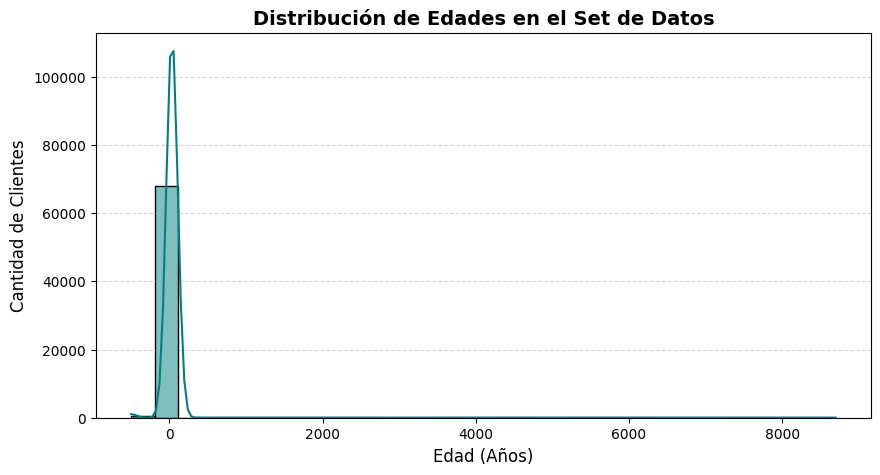

In [ ]:
# Age      
                    
data['Age'].unique()
# Configuración del tamaño del lienzo

plt.figure(figsize=(10, 5))

# Renderizado del histograma con curva de densidad suave (KDE)
sns.histplot(
    data=data, 
    x="Age", 
    bins=30, 
    kde=True, 
    color="teal", 
    edgecolor="black"
)

# Títulos y etiquetas del gráfico
plt.title("Distribución de Edades en el Set de Datos", fontsize=14, fontweight="bold")
plt.xlabel("Edad (Años)", fontsize=12)
plt.ylabel("Cantidad de Clientes", fontsize=12)

# Añadir una cuadrícula de fondo sutil para facilitar la lectura
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Mostrar el gráfico limpio en pantalla
plt.show()

In [ ]:
# Age 
# 1. Definimos las máscaras para identificar las edades corruptas
condicion_corrupta = (data["Age"] <= 0) | (data["Age"] >= 100)
print(f" Cantidad de registros con edades erróneas encontrados: {condicion_corrupta.sum()}")

# 2. Reemplazamos temporalmente las edades erróneas por NaN 
# Esto es vital para que no afecten el cálculo de la moda del cliente
data.loc[condicion_corrupta, "Age"] = np.nan

# 3. Calculamos la moda de la edad para cada Customer_ID
# Usamos una función lambda que extrae el primer valor de la moda si existe
moda_por_cliente = data.groupby("Customer_ID")["Age"].transform(
    lambda x: x.mode()[0] if not x.mode().empty else np.nan
)

# 4. Rellenamos las edades que habíamos borrado usando la moda de su respectivo ID
data["Age"] = data["Age"].fillna(moda_por_cliente)

# 5. RED DE SEGURIDAD GLOBAL: En caso extremo de que un cliente SOLO tenga edades corruptas en todo el año
mediana_global = data["Age"].median()
data["Age"] = data["Age"].fillna(mediana_global)

# 6. Nos aseguramos de que quede en formato entero limpio
data["Age"] = data["Age"].round().astype("Int64")

print(f" Corrección completada. Edades fuera de rango remanentes: {((data['Age'] <= 0) | (data['Age'] >= 100)).sum()}")


 Cantidad de registros con edades erróneas encontrados: 1928
 Corrección completada. Edades fuera de rango remanentes: 0


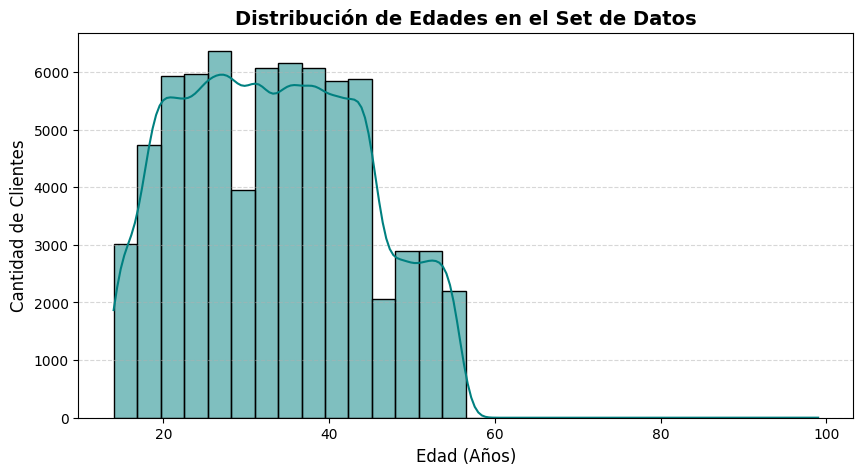

In [ ]:
# Age
plt.figure(figsize=(10, 5))

# Renderizado del histograma con curva de densidad suave (KDE)
sns.histplot(
    data=data, 
    x="Age", 
    bins=30, 
    kde=True, 
    color="teal", 
    edgecolor="black"
)

# Títulos y etiquetas del gráfico
plt.title("Distribución de Edades en el Set de Datos", fontsize=14, fontweight="bold")
plt.xlabel("Edad (Años)", fontsize=12)
plt.ylabel("Cantidad de Clientes", fontsize=12)

# Añadir una cuadrícula de fondo sutil para facilitar la lectura
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Mostrar el gráfico limpio en pantalla
plt.show()

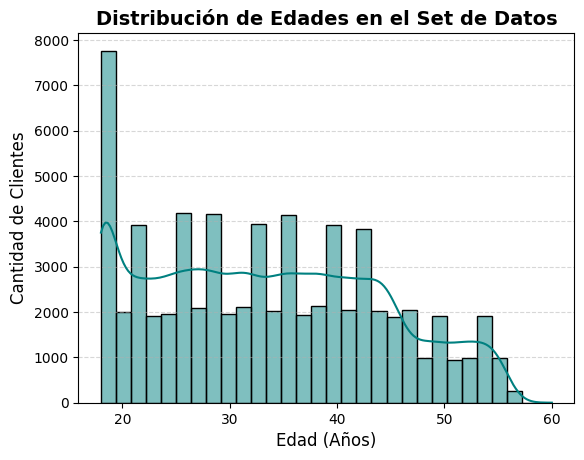

In [ ]:
# Age
data["Age"] = data["Age"].clip(lower=18, upper=60)

# Renderizado del histograma con curva de densidad suave (KDE)
sns.histplot(
    data=data, 
    x="Age", 
    bins=30, 
    kde=True, 
    color="teal", 
    edgecolor="black"
)

# Títulos y etiquetas del gráfico
plt.title("Distribución de Edades en el Set de Datos", fontsize=14, fontweight="bold")
plt.xlabel("Edad (Años)", fontsize=12)
plt.ylabel("Cantidad de Clientes", fontsize=12)

# Añadir una cuadrícula de fondo sutil para facilitar la lectura
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Mostrar el gráfico limpio en pantalla
plt.show()

In [ ]:
# Occupation

data['Occupation'].unique()

array(['Manager', 'Accountant', 'Engineer', 'Lawyer', 'Scientist',
       'Musician', 'Developer', 'Journalist', 'Mechanic', '_______',
       'Doctor', 'Media_Manager', 'Teacher', 'Writer', 'Entrepreneur',
       'Architect'], dtype=object)

In [ ]:

# 1. Limpieza inicial: Limpiamos espacios y convertimos los guiones bajos a NaN
data["Occupation"] = data["Occupation"].astype(str).str.strip()
data.loc[data["Occupation"] == "_______", "Occupation"] = np.nan

# 2. Calculamos la moda de la ocupación para cada Customer_ID
# Usamos una función lambda que extrae el primer valor de la moda si el cliente tiene registros válidos
moda_ocupacion_cliente = data.groupby("Customer_ID")["Occupation"].transform(
    lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan
)

# 3. Rellenamos las filas vacías usando la moda de su respectivo ID
data["Occupation"] = data["Occupation"].fillna(moda_ocupacion_cliente)


print(f"✅ Ocupaciones rellenadas. Valores nulos o corruptos remanentes: {data['Occupation'].isna().sum()}")

# Aquí eliminamos los  registros residuales que mencionas
data = data.dropna(subset=["Occupation"])

print(f"✅ Ocupaciones rellenadas. Valores nulos o corruptos remanentes: {data['Occupation'].isna().sum()}")



✅ Ocupaciones rellenadas. Valores nulos o corruptos remanentes: 5
✅ Ocupaciones rellenadas. Valores nulos o corruptos remanentes: 0


In [ ]:
# ==========================================
# SECCIÓN DE BLINDAJE: GENERACIÓN DE LISTA AUXILIAR
# ==========================================
# 1. Extraemos las profesiones únicas que sobrevivieron en el set de entrenamiento
lista_ocupaciones_aux = list(data["Occupation"].unique())

# 2. Blindaje: Si 'Unknown' no quedó en la lista de entrenamiento, la añadimos manualmente
# Esto asegura que cuando X_test use esta lista, tenga un número asignado para sus nulos
if "Unknown" not in lista_ocupaciones_aux:
    lista_ocupaciones_aux.append("Unknown")

print(f"🔒 Lista auxiliar de blindaje generada de forma exitosa.")
print(f"-> Total de categorías registradas para el modelo: {len(lista_ocupaciones_aux)}")
print(f"-> Categorías: {lista_ocupaciones_aux}")

# 3. Transformamos la columna del entrenamiento usando la lista auxiliar fija
data["Occupation"] = pd.Categorical(data["Occupation"], categories=lista_ocupaciones_aux)
data["Occupation"] = data["Occupation"].cat.codes


🔒 Lista auxiliar de blindaje generada de forma exitosa.
-> Total de categorías registradas para el modelo: 16
-> Categorías: ['Manager', 'Accountant', 'Engineer', 'Lawyer', 'Scientist', 'Musician', 'Developer', 'Journalist', 'Mechanic', 'Doctor', 'Media_Manager', 'Teacher', 'Writer', 'Entrepreneur', 'Architect', 'Unknown']


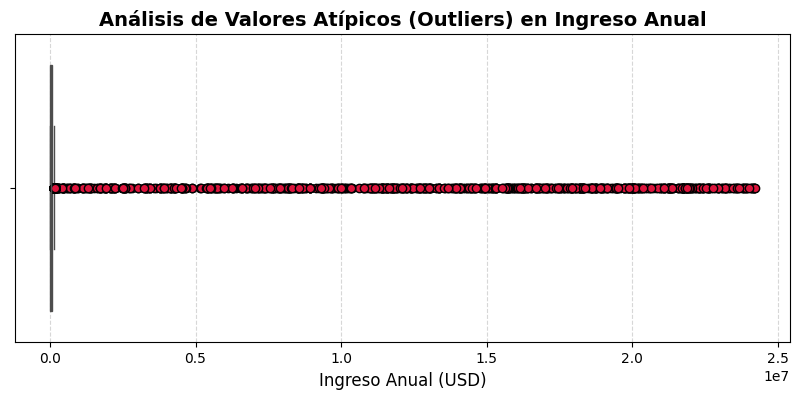

In [ ]:
# Annual_Income      
                    

# Configuración del tamaño del lienzo
plt.figure(figsize=(10, 4))

# Renderizado del boxplot horizontal con un color ámbar hexadecimal válido
sns.boxplot(
    data=data,
    x="Annual_Income",
    color="#FFBF00",  # Código Hexadecimal para el color Ámbar
    flierprops={"markerfacecolor": "crimson", "markeredgecolor": "black", "marker": "o"}
)

# Títulos y etiquetas claras
plt.title("Análisis de Valores Atípicos (Outliers) en Ingreso Anual", fontsize=14, fontweight="bold")
plt.xlabel("Ingreso Anual (USD)", fontsize=12)

# Añadir cuadrícula sutil en el eje X
plt.grid(axis="x", linestyle="--", alpha=0.5)

# Mostrar el gráfico en pantalla
plt.show()


In [ ]:
# 1. Calcular los cuartiles y el Rango Intercuartílico (IQR)
q25 = data["Annual_Income"].quantile(0.25)
q75 = data["Annual_Income"].quantile(0.75)
iqr = q75 - q25

# 2. Calcular las fronteras de corte teóricas de la regla de Tukey
lower_bound = q25 - 1.5 * iqr
upper_bound = q75 + 1.5 * iqr

# 3. Contar cuántos registros caen fuera de los límites establecidos
outliers_bajos = (data["Annual_Income"] < lower_bound).sum()
outliers_altos = (data["Annual_Income"] > upper_bound).sum()
total_outliers = outliers_bajos + outliers_altos
total_registros = len(data)

# 4. Desplegar el reporte completo de auditoría en pantalla
print("📊 Reporte de Auditoría de Outliers (Método IQR) para Annual_Income")
print("-" * 65)
print(f"🔹 Cuartil 25% (Q1)     : ${q25:,.2f}")
print(f"🔹 Cuartil 75% (Q3)     : ${q75:,.2f}")
print(f"🔹 Rango Intercuartílico: ${iqr:,.2f}")
print("-" * 65)
print(f"🚩 Umbral Límite Inferior (Menor a): ${lower_bound:,.2f}")
print(f"🚩 Umbral Límite Superior (Mayor a): ${upper_bound:,.2f}")
print("-" * 65)
print(f"❌ Datos que se borrarían en el extremo INFERIOR: {outliers_bajos} ({ (outliers_bajos / total_registros) * 100:.2f}%)")
print(f"❌ Datos que se borrarían en el extremo SUPERIOR: {outliers_altos} ({ (outliers_altos / total_registros) * 100:.2f}%)")
print(f"🚨 Total de registros en riesgo de eliminación   : {total_outliers} ({ (total_outliers / total_registros) * 100:.2f}%)")
print("-" * 65)


📊 Reporte de Auditoría de Outliers (Método IQR) para Annual_Income
-----------------------------------------------------------------
🔹 Cuartil 25% (Q1)     : $19,532.06
🔹 Cuartil 75% (Q3)     : $72,817.02
🔹 Rango Intercuartílico: $53,284.96
-----------------------------------------------------------------
🚩 Umbral Límite Inferior (Menor a): $-60,395.38
🚩 Umbral Límite Superior (Mayor a): $152,744.46
-----------------------------------------------------------------
❌ Datos que se borrarían en el extremo INFERIOR: 0 (0.00%)
❌ Datos que se borrarían en el extremo SUPERIOR: 1906 (2.72%)
🚨 Total de registros en riesgo de eliminación   : 1906 (2.72%)
-----------------------------------------------------------------


In [ ]:
# aplicar el recorte de valores extremos en la columna 'Annual_Income' 
data["Annual_Income"] = data["Annual_Income"].clip(upper=152744.46)

In [ ]:
# Monthly_Inhand_Salary
# 1. Calcular los cuartiles y el Rango Intercuartílico (IQR)
q25 = data["Monthly_Inhand_Salary"].quantile(0.25)
q75 = data["Monthly_Inhand_Salary"].quantile(0.75)
iqr = q75 - q25

# 2. Calcular las fronteras de corte teóricas de la regla de Tukey
lower_bound = q25 - 1.5 * iqr
upper_bound = q75 + 1.5 * iqr

# 3. Contar cuántos registros caen fuera de los límites establecidos
outliers_bajos = (data["Monthly_Inhand_Salary"] < lower_bound).sum()
outliers_altos = (data["Monthly_Inhand_Salary"] > upper_bound).sum()
total_outliers = outliers_bajos + outliers_altos
total_registros = len(data)

# 4. Desplegar el reporte completo de auditoría en pantalla
print("📊 Reporte de Auditoría de Outliers (Método IQR) para Monthly_Inhand_Salary")
print("-" * 65)
print(f"🔹 Cuartil 25% (Q1)     : ${q25:,.2f}")
print(f"🔹 Cuartil 75% (Q3)     : ${q75:,.2f}")
print(f"🔹 Rango Intercuartílico: ${iqr:,.2f}")
print("-" * 65)
print(f"🚩 Umbral Límite Inferior (Menor a): ${lower_bound:,.2f}")
print(f"🚩 Umbral Límite Superior (Mayor a): ${upper_bound:,.2f}")
print("-" * 65)
print(f"❌ Datos que se borrarían en el extremo INFERIOR: {outliers_bajos} ({ (outliers_bajos / total_registros) * 100:.2f}%)")
print(f"❌ Datos que se borrarían en el extremo SUPERIOR: {outliers_altos} ({ (outliers_altos / total_registros) * 100:.2f}%)")
print(f"🚨 Total de registros en riesgo de eliminación   : {total_outliers} ({ (total_outliers / total_registros) * 100:.2f}%)")
print("-" * 65)

📊 Reporte de Auditoría de Outliers (Método IQR) para Monthly_Inhand_Salary
-----------------------------------------------------------------
🔹 Cuartil 25% (Q1)     : $1,633.28
🔹 Cuartil 75% (Q3)     : $5,981.99
🔹 Rango Intercuartílico: $4,348.71
-----------------------------------------------------------------
🚩 Umbral Límite Inferior (Menor a): $-4,889.78
🚩 Umbral Límite Superior (Mayor a): $12,505.05
-----------------------------------------------------------------
❌ Datos que se borrarían en el extremo INFERIOR: 0 (0.00%)
❌ Datos que se borrarían en el extremo SUPERIOR: 1450 (2.07%)
🚨 Total de registros en riesgo de eliminación   : 1450 (2.07%)
-----------------------------------------------------------------


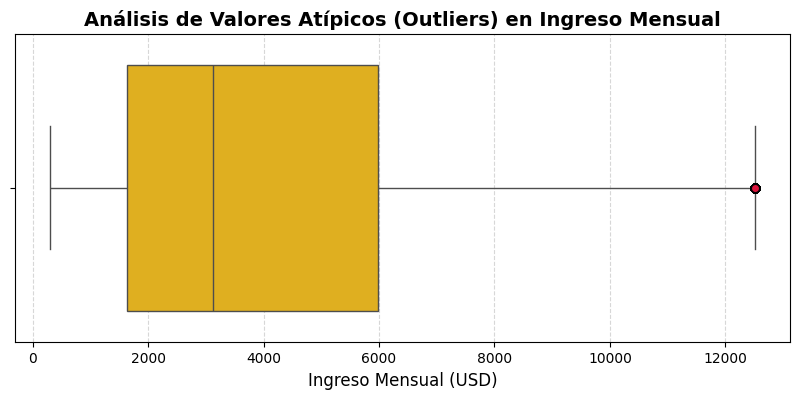

In [ ]:
# aplicar el recorte de valores extremos en la columna 'Monthly_Inhand_Salary' 
data["Monthly_Inhand_Salary"] = data["Monthly_Inhand_Salary"].clip(upper=12505.05)

# Configuración del tamaño del lienzo
plt.figure(figsize=(10, 4))

# Renderizado del boxplot horizontal con un color ámbar hexadecimal válido
sns.boxplot(
    data=data,
    x="Monthly_Inhand_Salary",
    color="#FFBF00",  # Código Hexadecimal para el color Ámbar
    flierprops={"markerfacecolor": "crimson", "markeredgecolor": "black", "marker": "o"}
)

# Títulos y etiquetas claras
plt.title("Análisis de Valores Atípicos (Outliers) en Ingreso Mensual", fontsize=14, fontweight="bold")
plt.xlabel("Ingreso Mensual (USD)", fontsize=12)

# Añadir cuadrícula sutil en el eje X
plt.grid(axis="x", linestyle="--", alpha=0.5)

# Mostrar el gráfico en pantalla
plt.show()

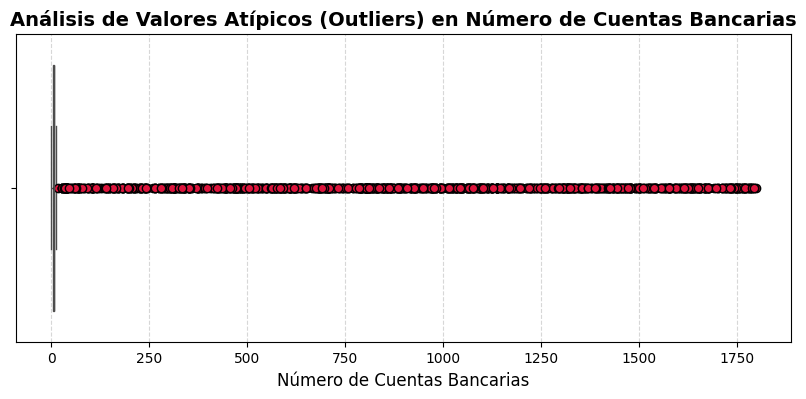

In [ ]:
# Num_Bank_Accounts
# Configuración del tamaño del lienzo
plt.figure(figsize=(10, 4))

# Renderizado del boxplot horizontal con un color ámbar hexadecimal válido
sns.boxplot(
    data=data,
    x="Num_Bank_Accounts",
    color="#FFBF00",  # Código Hexadecimal para el color Ámbar
    flierprops={"markerfacecolor": "crimson", "markeredgecolor": "black", "marker": "o"}
)

# Títulos y etiquetas claras
plt.title("Análisis de Valores Atípicos (Outliers) en Número de Cuentas Bancarias", fontsize=14, fontweight="bold")
plt.xlabel("Número de Cuentas Bancarias", fontsize=12)

# Añadir cuadrícula sutil en el eje X
plt.grid(axis="x", linestyle="--", alpha=0.5)

# Mostrar el gráfico en pantalla
plt.show()

In [ ]:
# 1. Contamos cuántos registros tienen más de 10 cuentas bancarias
outliers_cuentas = (data["Num_Bank_Accounts"] > 10).sum()
total_registros = len(data)

# 2. Calculamos los valores máximos reales para entender la gravedad del error
max_antes = data["Num_Bank_Accounts"].max()

# 3. Desplegamos el reporte de auditoría en pantalla
print("📊 Auditoría Estadística para Número de Cuentas Bancarias")
print("-" * 65)
print(f"🚨 Valor máximo absoluto detectado en el dataset: {max_antes} cuentas")
print("-" * 65)
print(f"❌ Registros con más de 10 cuentas (Outliers): {outliers_cuentas}")
print(f"📉 Porcentaje de datos afectados en el total : {(outliers_cuentas / total_registros) * 100:.2f}%")
print("-" * 65)


📊 Auditoría Estadística para Número de Cuentas Bancarias
-----------------------------------------------------------------
🚨 Valor máximo absoluto detectado en el dataset: 1798 cuentas
-----------------------------------------------------------------
❌ Registros con más de 10 cuentas (Outliers): 947
📉 Porcentaje de datos afectados en el total : 1.35%
-----------------------------------------------------------------


🔒 Columna 'Num_Bank_Accounts' blindada con éxito mediante Capping dual (0 - 10).
-> Nuevo valor mínimo: 0 cuentas
-> Nuevo valor máximo: 10 cuentas
-> Total de filas en tu DataFrame data: (69995, 29)


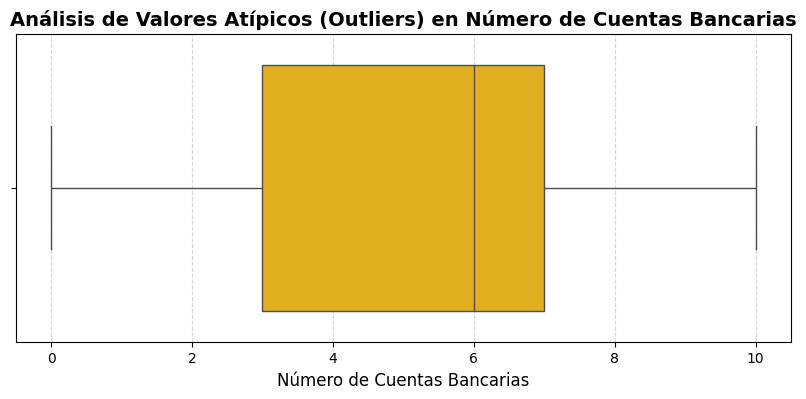

In [ ]:
# 1. Aplicamos el Capping lógico en 10 cuentas bancarias máximas
data["Num_Bank_Accounts"] = data["Num_Bank_Accounts"].clip(lower=0, upper=10)

print("🔒 Columna 'Num_Bank_Accounts' blindada con éxito mediante Capping dual (0 - 10).")
print(f"-> Nuevo valor mínimo: {data['Num_Bank_Accounts'].min()} cuentas")
print(f"-> Nuevo valor máximo: {data['Num_Bank_Accounts'].max()} cuentas")
print(f"-> Total de filas en tu DataFrame data: {data.shape}")


# Configuración del tamaño del lienzo
plt.figure(figsize=(10, 4))

# Renderizado del boxplot horizontal con un color ámbar hexadecimal válido
sns.boxplot(
    data=data,
    x="Num_Bank_Accounts",
    color="#FFBF00",  # Código Hexadecimal para el color Ámbar
    flierprops={"markerfacecolor": "crimson", "markeredgecolor": "black", "marker": "o"}
)

# Títulos y etiquetas claras
plt.title("Análisis de Valores Atípicos (Outliers) en Número de Cuentas Bancarias", fontsize=14, fontweight="bold")
plt.xlabel("Número de Cuentas Bancarias", fontsize=12)

# Añadir cuadrícula sutil en el eje X
plt.grid(axis="x", linestyle="--", alpha=0.5)

# Mostrar el gráfico en pantalla
plt.show()

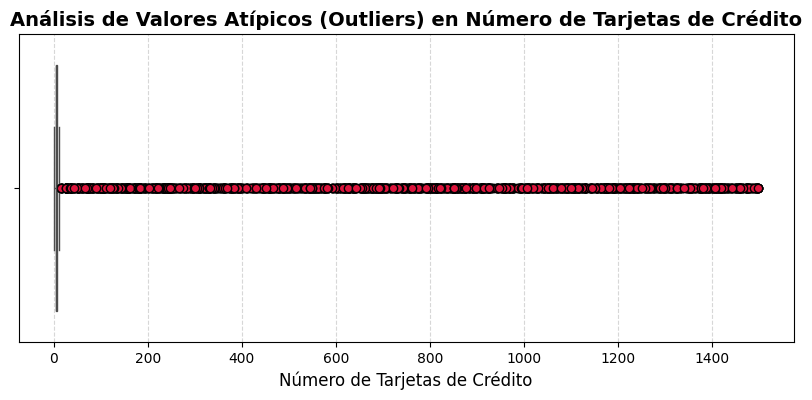

In [ ]:
# Num_Credit_Card
# Configuración del tamaño del lienzo
plt.figure(figsize=(10, 4))

# Renderizado del boxplot horizontal con un color ámbar hexadecimal válido
sns.boxplot(
    data=data,
    x="Num_Credit_Card",
    color="#FFBF00",  # Código Hexadecimal para el color Ámbar
    flierprops={"markerfacecolor": "crimson", "markeredgecolor": "black", "marker": "o"}
)

# Títulos y etiquetas claras
plt.title("Análisis de Valores Atípicos (Outliers) en Número de Tarjetas de Crédito", fontsize=14, fontweight="bold")
plt.xlabel("Número de Tarjetas de Crédito", fontsize=12)

# Añadir cuadrícula sutil en el eje X
plt.grid(axis="x", linestyle="--", alpha=0.5)

# Mostrar el gráfico en pantalla
plt.show()        

In [ ]:
# Num_Credit_Card
# 1. Contamos cuántos registros tienen más de 10 tarjetas de crédito
outliers_tarjetas = (data["Num_Credit_Card"] > 10).sum()
total_registros = len(data)

# 2. Calculamos los valores máximos reales para entender la gravedad del error
max_antes = data["Num_Credit_Card"].max()

# 3. Desplegamos el reporte de auditoría en pantalla
print("📊 Auditoría Estadística para Número de Tarjetas de Crédito")
print("-" * 65)
print(f"🚨 Valor máximo absoluto detectado en el dataset: {max_antes} tarjetas")
print("-" * 65)
print(f"❌ Registros con más de 10 tarjetas (Outliers): {outliers_tarjetas}")
print(f"📉 Porcentaje de datos afectados en el total : {(outliers_tarjetas / total_registros) * 100:.2f}%")
print("-" * 65)


📊 Auditoría Estadística para Número de Tarjetas de Crédito
-----------------------------------------------------------------
🚨 Valor máximo absoluto detectado en el dataset: 1499 tarjetas
-----------------------------------------------------------------
❌ Registros con más de 10 tarjetas (Outliers): 1623
📉 Porcentaje de datos afectados en el total : 2.32%
-----------------------------------------------------------------


In [ ]:
# Num_Credit_Card
# 2. Aplicar Capping inferior para corregir negativos (hacia 0)
data['Num_Credit_Card'] = data['Num_Credit_Card'].clip(lower=0)

# 3. Identificar errores masivos del sistema (> 10) y convertirlos en NaN
# (Usamos 10 como un límite humano razonable en el mercado financiero)
data.loc[data['Num_Credit_Card'] > 10, 'Num_Credit_Card'] = np.nan

# 4. Calcular la mediana matemática limpia basada en el perfil de riesgo
medianas_por_mix = data.groupby('Credit_Mix')['Num_Credit_Card'].transform('median')

# 5. Rellenar los NaN (los que venían vacíos + los errores del sistema borrados)
data['Num_Credit_Card'] = data['Num_Credit_Card'].fillna(medianas_por_mix)

# 6. En caso de que algún 'Credit_Mix' esté corrupto (como '_'), usamos la mediana global como respaldo
mediana_global = data['Num_Credit_Card'].median()
data['Num_Credit_Card'] = data['Num_Credit_Card'].fillna(mediana_global)

# 7. Formatear como entero puro (Int64)
data['Num_Credit_Card'] = data['Num_Credit_Card'].round().astype('Int64')

print("✅ Columna 'Num_Credit_Card' saneada de extremos, nulos y negativos.")
print(f"-> Rango final de tarjetas: de {data['Num_Credit_Card'].min()} a {data['Num_Credit_Card'].max()}")


✅ Columna 'Num_Credit_Card' saneada de extremos, nulos y negativos.
-> Rango final de tarjetas: de 0 a 10


In [ ]:
# Interest_Rate
# 1. Calcular los cuartiles y el Rango Intercuartílico (IQR)
q25 = data["Interest_Rate"].quantile(0.25)
q75 = data["Interest_Rate"].quantile(0.75)
iqr = q75 - q25

# 2. Calcular las fronteras de corte teóricas de la regla de Tukey
lower_bound = q25 - 1.5 * iqr
upper_bound = q75 + 1.5 * iqr

# 3. Contar cuántos registros caen fuera de los límites establecidos
outliers_bajos = (data["Interest_Rate"] < lower_bound).sum()
outliers_altos = (data["Interest_Rate"] > upper_bound).sum()
total_outliers = outliers_bajos + outliers_altos
total_registros = len(data)

# 4. Desplegar el reporte completo de auditoría en pantalla
print("📊 Reporte de Auditoría de Outliers (Método IQR) para Interest_Rate")
print("-" * 65)
print(f"🔹 Cuartil 25% (Q1)     : {q25:,.2f}")
print(f"🔹 Cuartil 75% (Q3)     : {q75:,.2f}")
print(f"🔹 Rango Intercuartílico: {iqr:,.2f}")
print("-" * 65)
print(f"🚩 Umbral Límite Inferior (Menor a): {lower_bound:,.2f}")
print(f"🚩 Umbral Límite Superior (Mayor a): {upper_bound:,.2f}")
print("-" * 65)
print(f"❌ Datos que se borrarían en el extremo INFERIOR: {outliers_bajos} ({ (outliers_bajos / total_registros) * 100:.2f}%)")
print(f"❌ Datos que se borrarían en el extremo SUPERIOR: {outliers_altos} ({ (outliers_altos / total_registros) * 100:.2f}%)")
print(f"🚨 Total de registros en riesgo de eliminación   : {total_outliers} ({ (total_outliers / total_registros) * 100:.2f}%)")
print("-" * 65)

📊 Reporte de Auditoría de Outliers (Método IQR) para Interest_Rate
-----------------------------------------------------------------
🔹 Cuartil 25% (Q1)     : 8.00
🔹 Cuartil 75% (Q3)     : 20.00
🔹 Rango Intercuartílico: 12.00
-----------------------------------------------------------------
🚩 Umbral Límite Inferior (Menor a): -10.00
🚩 Umbral Límite Superior (Mayor a): 38.00
-----------------------------------------------------------------
❌ Datos que se borrarían en el extremo INFERIOR: 0 (0.00%)
❌ Datos que se borrarían en el extremo SUPERIOR: 1447 (2.07%)
🚨 Total de registros en riesgo de eliminación   : 1447 (2.07%)
-----------------------------------------------------------------


In [ ]:
# Interest_Rate
# 1. Asegurar formato numérico
data['Interest_Rate'] = pd.to_numeric(data['Interest_Rate'], errors='coerce')

# 2. Blindaje inferior en 0% (Las tasas no pueden ser negativas)
data['Interest_Rate'] = data['Interest_Rate'].clip(lower=0)

# 3. Tratamiento de valores absurdos de sistema (ej. tasas mayores al 60%)
# En lugar de borrarlos del DataFrame, los pasamos a NaN para rescatar la fila
data.loc[data['Interest_Rate'] > 60, 'Interest_Rate'] = np.nan

# 4. Imputamos esos NaN con la mediana de su grupo de riesgo (Credit_Mix)
medianas_tasa_por_riesgo = data.groupby('Credit_Mix')['Interest_Rate'].transform('median')
data['Interest_Rate'] = data['Interest_Rate'].fillna(medianas_tasa_por_riesgo)

# Respala con la mediana global si el grupo está vacío
data['Interest_Rate'] = data['Interest_Rate'].fillna(data['Interest_Rate'].median())

print("🔒 Columna 'Interest_Rate' blindada con éxito mediante lógica financiera.")
print(f"-> Rango final de tasas: {data['Interest_Rate'].min()}% a {data['Interest_Rate'].max()}%")


🔒 Columna 'Interest_Rate' blindada con éxito mediante lógica financiera.
-> Rango final de tasas: 1.0% a 60.0%


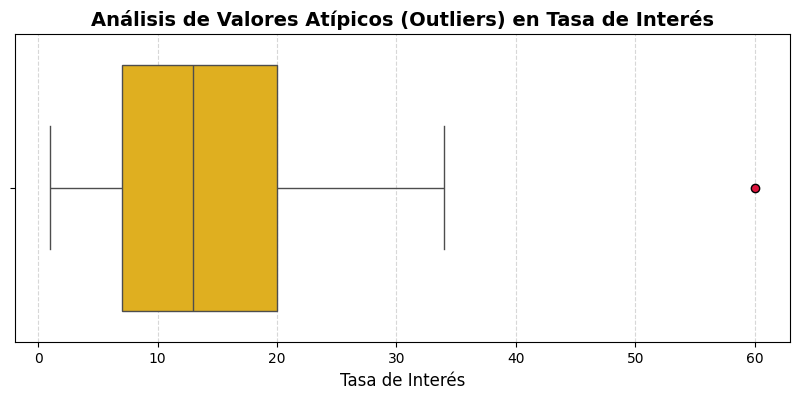

In [ ]:
# Interest_Rate
# Configuración del tamaño del lienzo
plt.figure(figsize=(10, 4))

# Renderizado del boxplot horizontal con un color ámbar hexadecimal válido
sns.boxplot(
    data=data,
    x="Interest_Rate",
    color="#FFBF00",  # Código Hexadecimal para el color Ámbar
    flierprops={"markerfacecolor": "crimson", "markeredgecolor": "black", "marker": "o"}
)

# Títulos y etiquetas claras
plt.title("Análisis de Valores Atípicos (Outliers) en Tasa de Interés", fontsize=14, fontweight="bold")
plt.xlabel("Tasa de Interés", fontsize=12)

# Añadir cuadrícula sutil en el eje X
plt.grid(axis="x", linestyle="--", alpha=0.5)

# Mostrar el gráfico en pantalla
plt.show()

In [ ]:
# Num_of_Loan
# Extrae solo los dígitos numéricos (\d+) y convierte la columna a entero puro
data['Num_of_Loan'] = data['Num_of_Loan'].astype(str).str.extract(r'(\d+)').astype('int64')

print("🚀 Conversión completada con Regex.")
print(f"-> Tipo de dato actual: {data['Num_of_Loan'].dtype}")
    

🚀 Conversión completada con Regex.
-> Tipo de dato actual: int64


In [ ]:
# Num_of_Loan
# 1. Calcular los cuartiles y el Rango Intercuartílico (IQR)
q25 = data["Num_of_Loan"].quantile(0.25)
q75 = data["Num_of_Loan"].quantile(0.75)
iqr = q75 - q25

# 2. Calcular las fronteras de corte teóricas de la regla de Tukey
lower_bound = q25 - 1.5 * iqr
upper_bound = q75 + 1.5 * iqr

# 3. Contar cuántos registros caen fuera de los límites establecidos
outliers_bajos = (data["Num_of_Loan"] < lower_bound).sum()
outliers_altos = (data["Num_of_Loan"] > upper_bound).sum()
total_outliers = outliers_bajos + outliers_altos
total_registros = len(data)

# 4. Desplegar el reporte completo de auditoría en pantalla
print("📊 Reporte de Auditoría de Outliers (Método IQR) para Num_of_Loan")
print("-" * 65)
print(f"🔹 Cuartil 25% (Q1)     : {q25:,.2f}")
print(f"🔹 Cuartil 75% (Q3)     : {q75:,.2f}")
print(f"🔹 Rango Intercuartílico: {iqr:,.2f}")
print("-" * 65)
print(f"🚩 Umbral Límite Inferior (Menor a): {lower_bound:,.2f}")
print(f"🚩 Umbral Límite Superior (Mayor a): {upper_bound:,.2f}")
print("-" * 65)
print(f"❌ Datos que se borrarían en el extremo INFERIOR: {outliers_bajos} ({ (outliers_bajos / total_registros) * 100:.2f}%)")
print(f"❌ Datos que se borrarían en el extremo SUPERIOR: {outliers_altos} ({ (outliers_altos / total_registros) * 100:.2f}%)")
print(f"🚨 Total de registros en riesgo de eliminación   : {total_outliers} ({ (total_outliers / total_registros) * 100:.2f}%)")
print("-" * 65)

📊 Reporte de Auditoría de Outliers (Método IQR) para Num_of_Loan
-----------------------------------------------------------------
🔹 Cuartil 25% (Q1)     : 2.00
🔹 Cuartil 75% (Q3)     : 6.00
🔹 Rango Intercuartílico: 4.00
-----------------------------------------------------------------
🚩 Umbral Límite Inferior (Menor a): -4.00
🚩 Umbral Límite Superior (Mayor a): 12.00
-----------------------------------------------------------------
❌ Datos que se borrarían en el extremo INFERIOR: 0 (0.00%)
❌ Datos que se borrarían en el extremo SUPERIOR: 3056 (4.37%)
🚨 Total de registros en riesgo de eliminación   : 3056 (4.37%)
-----------------------------------------------------------------


In [ ]:


# 1. Aplicamos tu enfoque quirúrgico de Regex para limpiar texto sucio (como '3_')
data['Num_of_Loan'] = data['Num_of_Loan'].astype(str).str.extract(r'(\d+)').astype(float)

# 2. Control de signos por si acaso (Mínimo 0 préstamos)
data['Num_of_Loan'] = data['Num_of_Loan'].clip(lower=0)

# 3. Aplicamos tu Umbral Definitivo de Negocio: Todo lo mayor a 12 se convierte en NaN
data.loc[data['Num_of_Loan'] > 12, 'Num_of_Loan'] = np.nan

# 4. Reconstruimos ese 4.36% de errores usando la mediana del grupo de riesgo (Credit_Mix)
medianas_por_mix = data.groupby('Credit_Mix')['Num_of_Loan'].transform('median')
data['Num_of_Loan'] = data['Num_of_Loan'].fillna(medianas_por_mix)

# 5. Respaldo estadístico global por seguridad
data['Num_of_Loan'] = data['Num_of_Loan'].fillna(data['Num_of_Loan'].median())

# 6. Conversión definitiva a entero puro (Int64)
data['Num_of_Loan'] = data['Num_of_Loan'].round().astype('Int64')

print("🔒 ¡Columna 'Num_of_Loan' blindada y convertida a entero con éxito!")
print(f"-> Nuevo rango de préstamos en el dataset: {data['Num_of_Loan'].min()} a {data['Num_of_Loan'].max()}")



🔒 ¡Columna 'Num_of_Loan' blindada y convertida a entero con éxito!
-> Nuevo rango de préstamos en el dataset: 0 a 9


In [ ]:
# Type_of_Loan
lista_tipos_prestamo = list(data["Type_of_Loan"].unique())
lista_tipos_prestamo

['Personal Loan, Not Specified, and Payday Loan',
 'None',
 'Debt Consolidation Loan, Credit-Builder Loan, and Home Equity Loan',
 'Debt Consolidation Loan, Not Specified, Credit-Builder Loan, and Not Specified',
 'Not Specified, and Mortgage Loan',
 'Debt Consolidation Loan, Payday Loan, Student Loan, and Not Specified',
 'Debt Consolidation Loan, Mortgage Loan, Credit-Builder Loan, and Debt Consolidation Loan',
 'Debt Consolidation Loan, Auto Loan, Auto Loan, and Student Loan',
 'Debt Consolidation Loan, and Auto Loan',
 'Auto Loan, Student Loan, Credit-Builder Loan, and Personal Loan',
 'Auto Loan, Credit-Builder Loan, Not Specified, Debt Consolidation Loan, Debt Consolidation Loan, Auto Loan, Mortgage Loan, Personal Loan, and Debt Consolidation Loan',
 'Mortgage Loan, Student Loan, and Debt Consolidation Loan',
 'Mortgage Loan, Auto Loan, and Personal Loan',
 'Debt Consolidation Loan, Personal Loan, Payday Loan, Home Equity Loan, Not Specified, Not Specified, and Home Equity Loan',

In [ ]:

# 1. Creamos el diccionario con las 9 categorías y sus puntuaciones exactas
diccionario_riesgo = {
    "Payday Loan": 1,
    "Not Specified": 1,
    "Personal Loan": 1,
    "Credit-Builder Loan": 1,
    "Debt Consolidation Loan": 2,
    "Auto Loan": 2,
    "Mortgage Loan": 3,
    "Home Equity Loan": 3,
    "Student Loan": 3,
}

# 2. Función matemática para calcular el Índice de Riesgo Promedio
def calcular_indice_prestamo(texto):
    if (
        pd.isna(texto)
        or str(texto).strip() in ["", "nan", "None", "_______"]
        or "none" in str(texto).lower()
    ):
        return 0.0  # Puntuación especial: Sin deudas (Riesgo Nulo)

    texto_limpio = str(texto).replace(" and ", ", ")
    partes = [p.strip() for p in texto_limpio.split(",") if p.strip()]

    suma_puntuaciones = 0
    conteo_prestamos = 0

    for prestamo in partes:
        if prestamo in diccionario_riesgo:
            suma_puntuaciones += diccionario_riesgo[prestamo]
            conteo_prestamos += 1

    if conteo_prestamos == 0:
        return 0.0

    return round(suma_puntuaciones / conteo_prestamos, 2)

# 3. CREACIÓN DE LAS NUEVAS VARIABLES (Conservando la columna original)
data["Loan_Risk_Index"] = data["Type_of_Loan"].apply(calcular_indice_prestamo)

data["Total_Active_Loans"] = data["Type_of_Loan"].apply(
    lambda x: (
        0
        if pd.isna(x) or str(x).strip() in ["", "nan", "None", "_______"]
        else len(str(x).replace(" and ", ", ").split(","))
    )
)

print("🎯 Nuevas variables numéricas generadas de forma impecable.")
# Mostramos la columna original junto a las nuevas para verificar la lógica visualmente
print(data[["Type_of_Loan", "Total_Active_Loans", "Loan_Risk_Index"]].head())


🎯 Nuevas variables numéricas generadas de forma impecable.
                                        Type_of_Loan  Total_Active_Loans  \
0      Personal Loan, Not Specified, and Payday Loan                   4   
1                                               None                   0   
2  Debt Consolidation Loan, Credit-Builder Loan, ...                   4   
3  Debt Consolidation Loan, Not Specified, Credit...                   5   
4                   Not Specified, and Mortgage Loan                   3   

   Loan_Risk_Index  
0             1.00  
1             0.00  
2             2.00  
3             1.25  
4             2.00  


In [ ]:
# Delay_from_due_date       
# 1. Calcular los cuartiles y el Rango Intercuartílico (IQR)
q25 = data["Delay_from_due_date"].quantile(0.25)
q75 = data["Delay_from_due_date"].quantile(0.75)
iqr = q75 - q25

# 2. Calcular las fronteras de corte teóricas de la regla de Tukey
lower_bound = q25 - 1.5 * iqr
upper_bound = q75 + 1.5 * iqr

# 3. Contar cuántos registros caen fuera de los límites establecidos
outliers_bajos = (data["Delay_from_due_date"] < lower_bound).sum()
outliers_altos = (data["Delay_from_due_date"] > upper_bound).sum()
total_outliers = outliers_bajos + outliers_altos
total_registros = len(data)

# 4. Desplegar el reporte completo de auditoría en pantalla
print("📊 Reporte de Auditoría de Outliers (Método IQR) para Delay_from_due_date")
print("-" * 65)
print(f"🔹 Cuartil 25% (Q1)     : {q25:,.2f}")
print(f"🔹 Cuartil 75% (Q3)     : {q75:,.2f}")
print(f"🔹 Rango Intercuartílico: {iqr:,.2f}")
print("-" * 65)
print(f"🚩 Umbral Límite Inferior (Menor a): {lower_bound:,.2f}")
print(f"🚩 Umbral Límite Superior (Mayor a): {upper_bound:,.2f}")
print("-" * 65)
print(f"❌ Datos que se borrarían en el extremo INFERIOR: {outliers_bajos} ({ (outliers_bajos / total_registros) * 100:.2f}%)")
print(f"❌ Datos que se borrarían en el extremo SUPERIOR: {outliers_altos} ({ (outliers_altos / total_registros) * 100:.2f}%)")
print(f"🚨 Total de registros en riesgo de eliminación   : {total_outliers} ({ (total_outliers / total_registros) * 100:.2f}%)")
print("-" * 65)

📊 Reporte de Auditoría de Outliers (Método IQR) para Delay_from_due_date
-----------------------------------------------------------------
🔹 Cuartil 25% (Q1)     : 10.00
🔹 Cuartil 75% (Q3)     : 28.00
🔹 Rango Intercuartílico: 18.00
-----------------------------------------------------------------
🚩 Umbral Límite Inferior (Menor a): -17.00
🚩 Umbral Límite Superior (Mayor a): 55.00
-----------------------------------------------------------------
❌ Datos que se borrarían en el extremo INFERIOR: 0 (0.00%)
❌ Datos que se borrarían en el extremo SUPERIOR: 2765 (3.95%)
🚨 Total de registros en riesgo de eliminación   : 2765 (3.95%)
-----------------------------------------------------------------


In [ ]:
# 1. Filtramos las filas que superan el límite superior de tu auditoría
retrasos_extremos = data[data["Delay_from_due_date"] > 55]["Delay_from_due_date"]

# 2. Imprimimos estadísticas básicas de este grupo y los valores más extravagantes
print("🔍 Inspección de Valores por Encima de 55 Días")
print("-" * 60)
print(f"🔹 Total de registros detectados: {len(retrasos_extremos)}")
print(f"🔹 Valor mínimo en este grupo   : {retrasos_extremos.min()} días")
print(f"🚨 Valor máximo absoluto        : {retrasos_extremos.max()} días")
print("-" * 60)
print("📋 Muestra de los 20 valores más altos (ordenados de mayor a menor):")
print(retrasos_extremos.sort_values(ascending=False).unique()[:20])
print("-" * 60)


🔍 Inspección de Valores por Encima de 55 Días
------------------------------------------------------------
🔹 Total de registros detectados: 2765
🔹 Valor mínimo en este grupo   : 56 días
🚨 Valor máximo absoluto        : 67 días
------------------------------------------------------------
📋 Muestra de los 20 valores más altos (ordenados de mayor a menor):
[67 66 65 64 63 62 61 60 59 58 57 56]
------------------------------------------------------------


In [ ]:
# 1. Aseguramos formato numérico puro
data["Delay_from_due_date"] = pd.to_numeric(data["Delay_from_due_date"], errors="coerce")

# 2. ESTRATEGIA ÓPTIMA: Colocamos 0 a los negativos, pero dejamos la cola superior intacta
data["Delay_from_due_date"] = data["Delay_from_due_date"].clip(lower=0)

# 3. Rellenamos posibles nulos residuales si existieran con la mediana
mediana_retraso = data["Delay_from_due_date"].median()
data["Delay_from_due_date"] = data["Delay_from_due_date"].fillna(mediana_retraso)

print("🔒 Variable 'Delay_from_due_date' procesada con la estrategia óptima.")
print(f"-> Rango real en entrenamiento: de {data['Delay_from_due_date'].min()} a {data['Delay_from_due_date'].max()} días.")


🔒 Variable 'Delay_from_due_date' procesada con la estrategia óptima.
-> Rango real en entrenamiento: de 0 a 67 días.


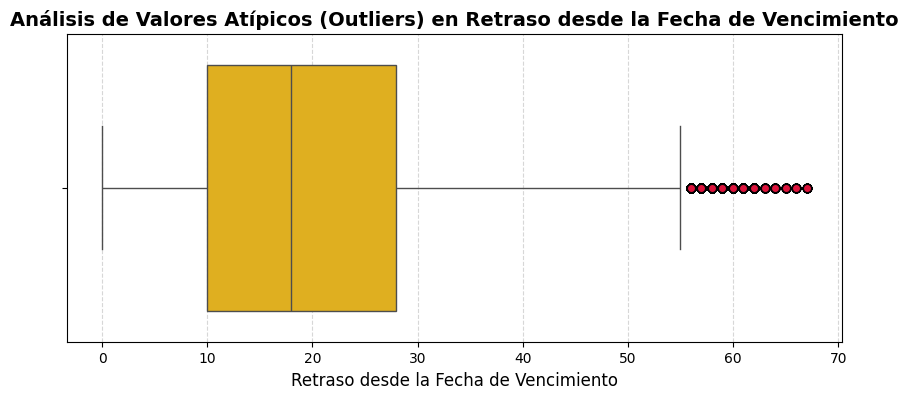

In [ ]:
# Configuración del tamaño del lienzo
plt.figure(figsize=(10, 4))

# Renderizado del boxplot horizontal con un color ámbar hexadecimal válido
sns.boxplot(
    data=data,
    x="Delay_from_due_date",
    color="#FFBF00",  # Código Hexadecimal para el color Ámbar
    flierprops={"markerfacecolor": "crimson", "markeredgecolor": "black", "marker": "o"}
)

# Títulos y etiquetas claras
plt.title("Análisis de Valores Atípicos (Outliers) en Retraso desde la Fecha de Vencimiento", fontsize=14, fontweight="bold")
plt.xlabel("Retraso desde la Fecha de Vencimiento", fontsize=12)

# Añadir cuadrícula sutil en el eje X
plt.grid(axis="x", linestyle="--", alpha=0.5)

# Mostrar el gráfico en pantalla
plt.show()

In [ ]:
# Num_of_Delayed_Payment

# ==========================================
# 1. EXTRACCIÓN BLINDADA CON REGEX
# ==========================================
# El patrón r'(\d+)' extrae únicamente la secuencia de dígitos numéricos,
# eliminando guiones bajos (como '16_') o cualquier otro carácter corrupto de texto.
data["Num_of_Delayed_Payment"] = data["Num_of_Delayed_Payment"].astype(str).str.extract(r'(\d+)')

# ==========================================
# 2. CONVERSIÓN Y RELLENO PERSONALIZADO POR CLIENTE
# ==========================================
# Pasamos la columna a tipo numérico puro
data["Num_of_Delayed_Payment"] = pd.to_numeric(data["Num_of_Delayed_Payment"], errors="coerce")

# Imputamos los nulos usando la mediana de los otros meses del mismo cliente (Customer_ID)
mediana_pagos_cliente = data.groupby("Customer_ID")["Num_of_Delayed_Payment"].transform("median")
data["Num_of_Delayed_Payment"] = data["Num_of_Delayed_Payment"].fillna(mediana_pagos_cliente)

# Red de seguridad global por si algún cliente no tiene ningún registro válido en el año
mediana_pagos_global = data["Num_of_Delayed_Payment"].median()
data["Num_of_Delayed_Payment"] = data["Num_of_Delayed_Payment"].fillna(mediana_pagos_global)

# ==========================================
# 3. FORMATO FINAL A ENTERO PURO (Int64)
# ==========================================
# Redondeamos y convertimos a entero permitiendo nulos por seguridad estructural
data["Num_of_Delayed_Payment"] = data["Num_of_Delayed_Payment"].round().astype("Int64")

print("🎯 Columna 'Num_of_Delayed_Payment' extraída y convertida a entero con éxito.")

🎯 Columna 'Num_of_Delayed_Payment' extraída y convertida a entero con éxito.


In [ ]:
# Num_of_Delayed_Payment
# 1. Calcular los cuartiles y el Rango Intercuartílico (IQR)
q25 = data["Num_of_Delayed_Payment"].quantile(0.25)
q75 = data["Num_of_Delayed_Payment"].quantile(0.75)
iqr = q75 - q25

# 2. Calcular las fronteras de corte teóricas de la regla de Tukey
lower_bound = q25 - 1.5 * iqr
upper_bound = q75 + 1.5 * iqr

# 3. Contar cuántos registros caen fuera de los límites establecidos
outliers_bajos = (data["Num_of_Delayed_Payment"] < lower_bound).sum()
outliers_altos = (data["Num_of_Delayed_Payment"] > upper_bound).sum()
total_outliers = outliers_bajos + outliers_altos
total_registros = len(data)

# 4. Desplegar el reporte completo de auditoría en pantalla
print("📊 Reporte de Auditoría de Outliers (Método IQR) para Num_of_Delayed_Payment")
print("-" * 65)
print(f"🔹 Cuartil 25% (Q1)     : {q25:,.2f}")
print(f"🔹 Cuartil 75% (Q3)     : {q75:,.2f}")
print(f"🔹 Rango Intercuartílico: {iqr:,.2f}")
print("-" * 65)
print(f"🚩 Umbral Límite Inferior (Menor a): {lower_bound:,.2f}")
print(f"🚩 Umbral Límite Superior (Mayor a): {upper_bound:,.2f}")
print("-" * 65)
print(f"❌ Datos que se borrarían en el extremo INFERIOR: {outliers_bajos} ({ (outliers_bajos / total_registros) * 100:.2f}%)")
print(f"❌ Datos que se borrarían en el extremo SUPERIOR: {outliers_altos} ({ (outliers_altos / total_registros) * 100:.2f}%)")
print(f"🚨 Total de registros en riesgo de eliminación   : {total_outliers} ({ (total_outliers / total_registros) * 100:.2f}%)")
print("-" * 65)

📊 Reporte de Auditoría de Outliers (Método IQR) para Num_of_Delayed_Payment
-----------------------------------------------------------------
🔹 Cuartil 25% (Q1)     : 9.00
🔹 Cuartil 75% (Q3)     : 18.00
🔹 Rango Intercuartílico: 9.00
-----------------------------------------------------------------
🚩 Umbral Límite Inferior (Menor a): -4.50
🚩 Umbral Límite Superior (Mayor a): 31.50
-----------------------------------------------------------------
❌ Datos que se borrarían en el extremo INFERIOR: 0 (0.00%)
❌ Datos que se borrarían en el extremo SUPERIOR: 528 (0.75%)
🚨 Total de registros en riesgo de eliminación   : 528 (0.75%)
-----------------------------------------------------------------


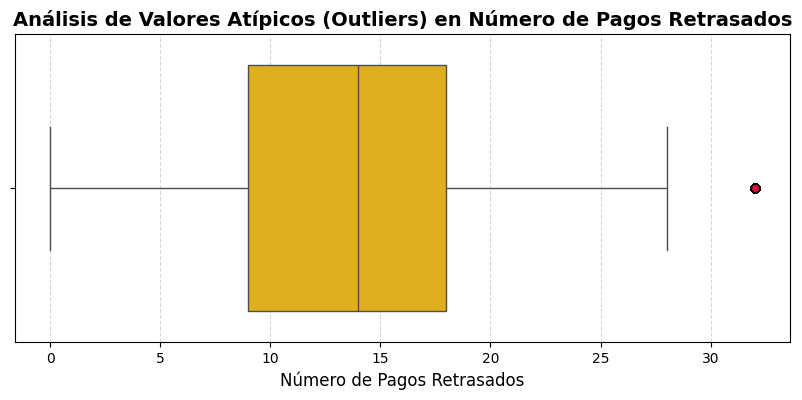

In [ ]:
# Forzamos que el mínimo sea 0 y el máximo sea 32
data["Num_of_Delayed_Payment"] = data["Num_of_Delayed_Payment"].clip(lower=0, upper=32)

#Num_of_Delayed_Payment
# Configuración del tamaño del lienzo
plt.figure(figsize=(10, 4))

# Renderizado del boxplot horizontal con un color ámbar hexadecimal válido
sns.boxplot(
    data=data,
    x="Num_of_Delayed_Payment",
    color="#FFBF00",  # Código Hexadecimal para el color Ámbar
    flierprops={"markerfacecolor": "crimson", "markeredgecolor": "black", "marker": "o"}
)

# Títulos y etiquetas claras
plt.title("Análisis de Valores Atípicos (Outliers) en Número de Pagos Retrasados", fontsize=14, fontweight="bold")
plt.xlabel("Número de Pagos Retrasados", fontsize=12)

# Añadir cuadrícula sutil en el eje X
plt.grid(axis="x", linestyle="--", alpha=0.5)

# Mostrar el gráfico en pantalla
plt.show()

In [ ]:
# Changed_Credit_Limit 

# ==========================================
# 1. LIMPIEZA CON REGEX: Conservamos números y el punto decimal
# ==========================================
# El patrón r'([0-9.]+)' extrae los dígitos y los puntos, ignorando guiones bajos (_)
data["Changed_Credit_Limit"] = data["Changed_Credit_Limit"].astype(str).str.extract(r'([0-9.]+)')

# ==========================================
# 2. CONVERSIÓN A FLOTANTE PURO (float64)
# ==========================================
data["Changed_Credit_Limit"] = pd.to_numeric(data["Changed_Credit_Limit"], errors="coerce")



In [ ]:
# Changed_Credit_Limit 

# 1. Calcular los cuartiles y el Rango Intercuartílico (IQR)
q25 = data["Changed_Credit_Limit"].quantile(0.25)
q75 = data["Changed_Credit_Limit"].quantile(0.75)
iqr = q75 - q25

# 2. Calcular las fronteras de corte teóricas de la regla de Tukey
lower_bound = q25 - 1.5 * iqr
upper_bound = q75 + 1.5 * iqr

# 3. Contar cuántos registros caen fuera de los límites establecidos
outliers_bajos = (data["Changed_Credit_Limit"] < lower_bound).sum()
outliers_altos = (data["Changed_Credit_Limit"] > upper_bound).sum()
total_outliers = outliers_bajos + outliers_altos
total_registros = len(data)

# 4. Desplegar el reporte completo de auditoría en pantalla
print("📊 Reporte de Auditoría de Outliers (Método IQR) para Changed_Credit_Limit")
print("-" * 65)
print(f"🔹 Cuartil 25% (Q1)     : {q25:,.2f}")
print(f"🔹 Cuartil 75% (Q3)     : {q75:,.2f}")
print(f"🔹 Rango Intercuartílico: {iqr:,.2f}")
print("-" * 65)
print(f"🚩 Umbral Límite Inferior (Menor a): {lower_bound:,.2f}")
print(f"🚩 Umbral Límite Superior (Mayor a): {upper_bound:,.2f}")
print("-" * 65)
print(f"❌ Datos que se borrarían en el extremo INFERIOR: {outliers_bajos} ({ (outliers_bajos / total_registros) * 100:.2f}%)")
print(f"❌ Datos que se borrarían en el extremo SUPERIOR: {outliers_altos} ({ (outliers_altos / total_registros) * 100:.2f}%)")
print(f"🚨 Total de registros en riesgo de eliminación   : {total_outliers} ({ (total_outliers / total_registros) * 100:.2f}%)")
print("-" * 65)

📊 Reporte de Auditoría de Outliers (Método IQR) para Changed_Credit_Limit
-----------------------------------------------------------------
🔹 Cuartil 25% (Q1)     : 5.36
🔹 Cuartil 75% (Q3)     : 14.86
🔹 Rango Intercuartílico: 9.50
-----------------------------------------------------------------
🚩 Umbral Límite Inferior (Menor a): -8.89
🚩 Umbral Límite Superior (Mayor a): 29.11
-----------------------------------------------------------------
❌ Datos que se borrarían en el extremo INFERIOR: 0 (0.00%)
❌ Datos que se borrarían en el extremo SUPERIOR: 477 (0.68%)
🚨 Total de registros en riesgo de eliminación   : 477 (0.68%)
-----------------------------------------------------------------


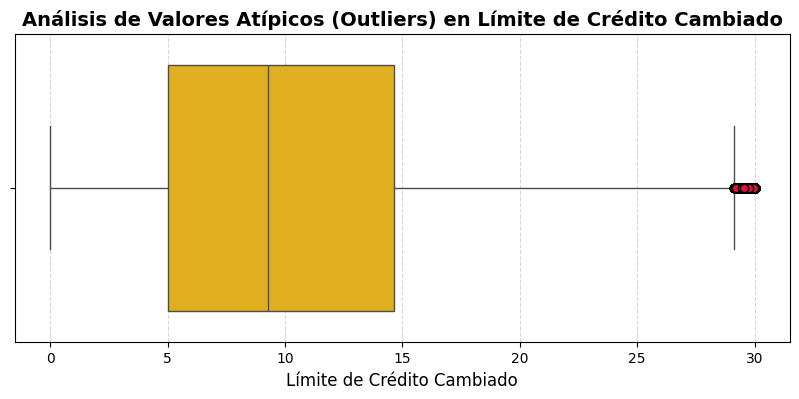

In [ ]:
# 1. Aseguramos extracción limpia con Regex (por si quedaban caracteres sucios)
data["Changed_Credit_Limit"] = data["Changed_Credit_Limit"].astype(str).str.extract(r"([0-9.]+)")
data["Changed_Credit_Limit"] = pd.to_numeric(data["Changed_Credit_Limit"], errors="coerce")

# ==========================================================
# 2. ESTRATEGIA ÓPTIMA FUSIONADA: Imputación Lógica + Capping Dual
# ==========================================================
# Primero rellenamos los vacíos con 0.0 (Lógica: No hubo cambio de límite)
# E inmediatamente después acotamos el rango entre 0.0 y 30.0 (Capping de tu auditoría)
data["Changed_Credit_Limit"] = data["Changed_Credit_Limit"].fillna(0.0).clip(lower=0.0, upper=30.0)

#Changed_Credit_Limit
# Configuración del tamaño del lienzo
plt.figure(figsize=(10, 4))

# Renderizado del boxplot horizontal con un color ámbar hexadecimal válido
sns.boxplot(
    data=data,
    x="Changed_Credit_Limit",
    color="#FFBF00",  # Código Hexadecimal para el color Ámbar
    flierprops={"markerfacecolor": "crimson", "markeredgecolor": "black", "marker": "o"}
)

# Títulos y etiquetas claras
plt.title("Análisis de Valores Atípicos (Outliers) en Límite de Crédito Cambiado", fontsize=14, fontweight="bold")
plt.xlabel("Límite de Crédito Cambiado", fontsize=12)

# Añadir cuadrícula sutil en el eje X
plt.grid(axis="x", linestyle="--", alpha=0.5)

# Mostrar el gráfico en pantalla
plt.show()

In [ ]:
# Num_Credit_Inquiries
# 1. Calcular los cuartiles y el Rango Intercuartílico (IQR)
q25 = data["Num_Credit_Inquiries"].quantile(0.25)
q75 = data["Num_Credit_Inquiries"].quantile(0.75)
iqr = q75 - q25

# 2. Calcular las fronteras de corte teóricas de la regla de Tukey
lower_bound = q25 - 1.5 * iqr
upper_bound = q75 + 1.5 * iqr

# 3. Contar cuántos registros caen fuera de los límites establecidos
outliers_bajos = (data["Num_Credit_Inquiries"] < lower_bound).sum()
outliers_altos = (data["Num_Credit_Inquiries"] > upper_bound).sum()
total_outliers = outliers_bajos + outliers_altos
total_registros = len(data)

# 4. Desplegar el reporte completo de auditoría en pantalla
print("📊 Reporte de Auditoría de Outliers (Método IQR) para Num_Credit_Inquiries")
print("-" * 65)
print(f"🔹 Cuartil 25% (Q1)     : {q25:,.2f}")
print(f"🔹 Cuartil 75% (Q3)     : {q75:,.2f}")
print(f"🔹 Rango Intercuartílico: {iqr:,.2f}")
print("-" * 65)
print(f"🚩 Umbral Límite Inferior (Menor a): {lower_bound:,.2f}")
print(f"🚩 Umbral Límite Superior (Mayor a): {upper_bound:,.2f}")
print("-" * 65)
print(f"❌ Datos que se borrarían en el extremo INFERIOR: {outliers_bajos} ({ (outliers_bajos / total_registros) * 100:.2f}%)")
print(f"❌ Datos que se borrarían en el extremo SUPERIOR: {outliers_altos} ({ (outliers_altos / total_registros) * 100:.2f}%)")
print(f"🚨 Total de registros en riesgo de eliminación   : {total_outliers} ({ (total_outliers / total_registros) * 100:.2f}%)")
print("-" * 65)

📊 Reporte de Auditoría de Outliers (Método IQR) para Num_Credit_Inquiries
-----------------------------------------------------------------
🔹 Cuartil 25% (Q1)     : 3.00
🔹 Cuartil 75% (Q3)     : 9.00
🔹 Rango Intercuartílico: 6.00
-----------------------------------------------------------------
🚩 Umbral Límite Inferior (Menor a): -6.00
🚩 Umbral Límite Superior (Mayor a): 18.00
-----------------------------------------------------------------
❌ Datos que se borrarían en el extremo INFERIOR: 0 (0.00%)
❌ Datos que se borrarían en el extremo SUPERIOR: 1181 (1.69%)
🚨 Total de registros en riesgo de eliminación   : 1181 (1.69%)
-----------------------------------------------------------------


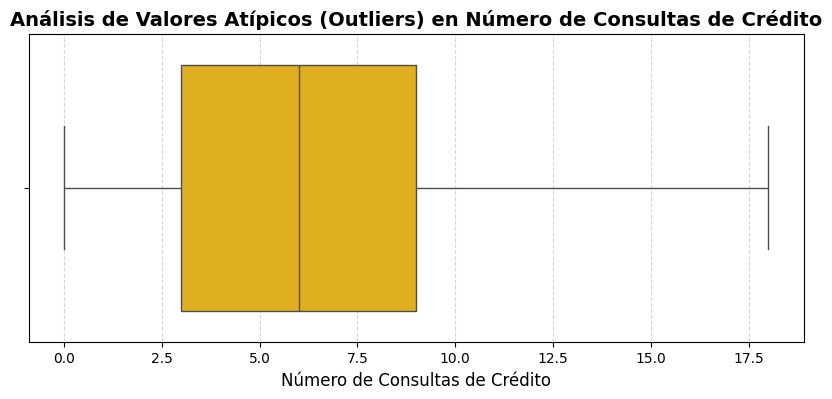

In [ ]:
# 1. Aplicamos el Capping basado en tu auditoría IQR (límite superior de 18 consultas)
# Forzamos que el mínimo sea 0 y el máximo sea 18
data["Num_Credit_Inquiries"] = data["Num_Credit_Inquiries"].clip(lower=0, upper=18)

#Num_Credit_Inquiries
# Configuración del tamaño del lienzo
plt.figure(figsize=(10, 4))

# Renderizado del boxplot horizontal con un color ámbar hexadecimal válido
sns.boxplot(
    data=data,
    x="Num_Credit_Inquiries",
    color="#FFBF00",  # Código Hexadecimal para el color Ámbar
    flierprops={"markerfacecolor": "crimson", "markeredgecolor": "black", "marker": "o"}
)

# Títulos y etiquetas claras
plt.title("Análisis de Valores Atípicos (Outliers) en Número de Consultas de Crédito", fontsize=14, fontweight="bold")
plt.xlabel("Número de Consultas de Crédito", fontsize=12)

# Añadir cuadrícula sutil en el eje X
plt.grid(axis="x", linestyle="--", alpha=0.5)

# Mostrar el gráfico en pantalla
plt.show()

In [ ]:
# Credit_Mix
data["Credit_Mix"] .unique()

array(['Good', '_', 'Standard', 'Bad'], dtype=object)

In [ ]:
# 1. Contamos la frecuencia exacta de cada categoría original
conteo_categorias = data["Credit_Mix"].astype(str).str.strip().value_counts()

# 2. Aislamos el caso corrupto '_' para medir su impacto
total_vacios = conteo_categorias.get("_", 0)
total_registros = len(data)
porcentaje_vacios = (total_vacios / total_registros) * 100

# 3. Desplegamos el reporte en pantalla
print("📊 Diagnóstico de Datos Corruptos para Credit_Mix")
print("-" * 60)
print("📋 Distribución actual en el dataset (incluyendo errores):")
print(conteo_categorias)
print("-" * 60)
print(f"🚩 Registros sin datos reales ('_')  : {total_vacios}")
print(f"📉 Porcentaje de pérdida en entrenamiento: {porcentaje_vacios:.2f}%")
print("-" * 60)


📊 Diagnóstico de Datos Corruptos para Credit_Mix
------------------------------------------------------------
📋 Distribución actual en el dataset (incluyendo errores):
Credit_Mix
Standard    25527
Good        17147
_           14142
Bad         13179
Name: count, dtype: int64
------------------------------------------------------------
🚩 Registros sin datos reales ('_')  : 14142
📉 Porcentaje de pérdida en entrenamiento: 20.20%
------------------------------------------------------------


In [ ]:

# 1. LIMPIEZA INICIAL: Convertimos los guiones bajos '_' en la categoría 'Unknown'
data["Credit_Mix"] = data["Credit_Mix"].astype(str).str.strip()
data["Credit_Mix"] = data["Credit_Mix"].replace(["_", "nan", "", "_______"], "Unknown")

# 2. MAPEO ORDINAL DE RIESGO BLINDADO:
# Asignamos un número fijo a cada perfil. Dejamos a 'Unknown' con su propio código.
mapa_credit_mix = {
    "Unknown": 0,
    "Bad": 1,
    "Standard": 2,
    "Good": 3
}

# 3. Aplicamos la transformación numérica directa sobre entrenamiento
data["Credit_Mix"] = data["Credit_Mix"].map(mapa_credit_mix)

print("🎯 Columna 'Credit_Mix' codificada exitosamente con el criterio de categoría 'Unknown'.")
print("📋 Nueva distribución numérica en entrenamiento:")
print(data["Credit_Mix"].value_counts())


🎯 Columna 'Credit_Mix' codificada exitosamente con el criterio de categoría 'Unknown'.
📋 Nueva distribución numérica en entrenamiento:
Credit_Mix
2    25527
3    17147
0    14142
1    13179
Name: count, dtype: int64


In [ ]:
# Outstanding_Debt

# El patrón r'([0-9.]+)' extrae secuencias numéricas con decimales,
# ignorando de golpe los guiones bajos (como '345.22_') o cualquier texto sucio.
data["Outstanding_Debt"] = data["Outstanding_Debt"].astype(str).str.extract(r'([0-9.]+)')

# Pasamos el texto limpio a números flotantes reales
data["Outstanding_Debt"] = pd.to_numeric(data["Outstanding_Debt"], errors="coerce")



In [ ]:
# Outstanding_Debt
# 1. Calcular los cuartiles y el Rango Intercuartílico (IQR)
q25 = data["Outstanding_Debt"].quantile(0.25)
q75 = data["Outstanding_Debt"].quantile(0.75)
iqr = q75 - q25

# 2. Calcular las fronteras de corte teóricas de la regla de Tukey
lower_bound = q25 - 1.5 * iqr
upper_bound = q75 + 1.5 * iqr

# 3. Contar cuántos registros caen fuera de los límites establecidos
outliers_bajos = (data["Outstanding_Debt"] < lower_bound).sum()
outliers_altos = (data["Outstanding_Debt"] > upper_bound).sum()
total_outliers = outliers_bajos + outliers_altos
total_registros = len(data)

# 4. Desplegar el reporte completo de auditoría en pantalla
print("📊 Reporte de Auditoría de Outliers (Método IQR) para Outstanding_Debt")
print("-" * 65)
print(f"🔹 Cuartil 25% (Q1)     : {q25:,.2f}")
print(f"🔹 Cuartil 75% (Q3)     : {q75:,.2f}")
print(f"🔹 Rango Intercuartílico: {iqr:,.2f}")
print("-" * 65)
print(f"🚩 Umbral Límite Inferior (Menor a): {lower_bound:,.2f}")
print(f"🚩 Umbral Límite Superior (Mayor a): {upper_bound:,.2f}")
print("-" * 65)
print(f"❌ Datos que se borrarían en el extremo INFERIOR: {outliers_bajos} ({ (outliers_bajos / total_registros) * 100:.2f}%)")
print(f"❌ Datos que se borrarían en el extremo SUPERIOR: {outliers_altos} ({ (outliers_altos / total_registros) * 100:.2f}%)")
print(f"🚨 Total de registros en riesgo de eliminación   : {total_outliers} ({ (total_outliers / total_registros) * 100:.2f}%)")
print("-" * 65)

📊 Reporte de Auditoría de Outliers (Método IQR) para Outstanding_Debt
-----------------------------------------------------------------
🔹 Cuartil 25% (Q1)     : 563.69
🔹 Cuartil 75% (Q3)     : 1,933.90
🔹 Rango Intercuartílico: 1,370.21
-----------------------------------------------------------------
🚩 Umbral Límite Inferior (Menor a): -1,491.62
🚩 Umbral Límite Superior (Mayor a): 3,989.22
-----------------------------------------------------------------
❌ Datos que se borrarían en el extremo INFERIOR: 0 (0.00%)
❌ Datos que se borrarían en el extremo SUPERIOR: 3707 (5.30%)
🚨 Total de registros en riesgo de eliminación   : 3707 (5.30%)
-----------------------------------------------------------------


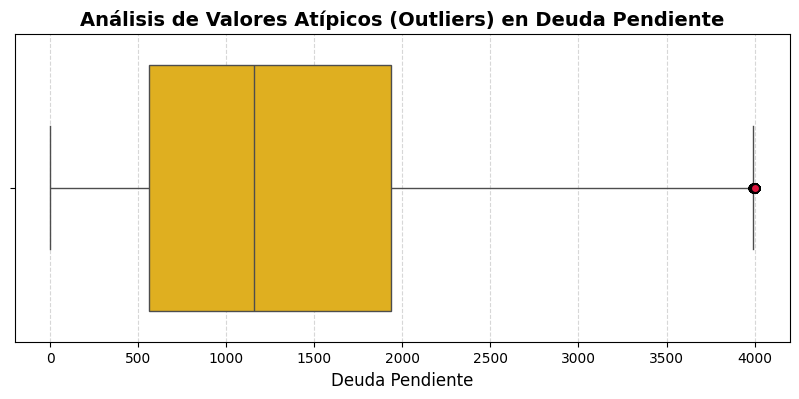

In [ ]:
# 1. Aplicamos el Capping basado en tu auditoría IQR (límite superior redondeado a 4000.0)
# Acotamos el mínimo a 0.0 y el máximo a 4000.0 manteniendo la escala flotante
data["Outstanding_Debt"] = data["Outstanding_Debt"].clip(lower=0.0, upper=4000.0)

#Outstanding_Debt
# Configuración del tamaño del lienzo
plt.figure(figsize=(10, 4))

# Renderizado del boxplot horizontal con un color ámbar hexadecimal válido
sns.boxplot(
    data=data,
    x="Outstanding_Debt",
    color="#FFBF00",  # Código Hexadecimal para el color Ámbar
    flierprops={"markerfacecolor": "crimson", "markeredgecolor": "black", "marker": "o"}
)

# Títulos y etiquetas claras
plt.title("Análisis de Valores Atípicos (Outliers) en Deuda Pendiente", fontsize=14, fontweight="bold")
plt.xlabel("Deuda Pendiente", fontsize=12)

# Añadir cuadrícula sutil en el eje X
plt.grid(axis="x", linestyle="--", alpha=0.5)

# Mostrar el gráfico en pantalla
plt.show()


In [ ]:
# Credit_Utilization_Ratio
# 1. Calcular los cuartiles y el Rango Intercuartílico (IQR)
q25 = data["Credit_Utilization_Ratio"].quantile(0.25)
q75 = data["Credit_Utilization_Ratio"].quantile(0.75)
iqr = q75 - q25

# 2. Calcular las fronteras de corte teóricas de la regla de Tukey
lower_bound = q25 - 1.5 * iqr
upper_bound = q75 + 1.5 * iqr

# 3. Contar cuántos registros caen fuera de los límites establecidos
outliers_bajos = (data["Credit_Utilization_Ratio"] < lower_bound).sum()
outliers_altos = (data["Credit_Utilization_Ratio"] > upper_bound).sum()
total_outliers = outliers_bajos + outliers_altos
total_registros = len(data)

# 4. Desplegar el reporte completo de auditoría en pantalla
print("📊 Reporte de Auditoría de Outliers (Método IQR) para Credit_Utilization_Ratio")
print("-" * 65)
print(f"🔹 Cuartil 25% (Q1)     : {q25:,.2f}")
print(f"🔹 Cuartil 75% (Q3)     : {q75:,.2f}")
print(f"🔹 Rango Intercuartílico: {iqr:,.2f}")
print("-" * 65)
print(f"🚩 Umbral Límite Inferior (Menor a): {lower_bound:,.2f}")
print(f"🚩 Umbral Límite Superior (Mayor a): {upper_bound:,.2f}")
print("-" * 65)
print(f"❌ Datos que se borrarían en el extremo INFERIOR: {outliers_bajos} ({ (outliers_bajos / total_registros) * 100:.2f}%)")
print(f"❌ Datos que se borrarían en el extremo SUPERIOR: {outliers_altos} ({ (outliers_altos / total_registros) * 100:.2f}%)")
print(f"🚨 Total de registros en riesgo de eliminación   : {total_outliers} ({ (total_outliers / total_registros) * 100:.2f}%)")
print("-" * 65)

📊 Reporte de Auditoría de Outliers (Método IQR) para Credit_Utilization_Ratio
-----------------------------------------------------------------
🔹 Cuartil 25% (Q1)     : 28.05
🔹 Cuartil 75% (Q3)     : 36.51
🔹 Rango Intercuartílico: 8.46
-----------------------------------------------------------------
🚩 Umbral Límite Inferior (Menor a): 15.36
🚩 Umbral Límite Superior (Mayor a): 49.20
-----------------------------------------------------------------
❌ Datos que se borrarían en el extremo INFERIOR: 0 (0.00%)
❌ Datos que se borrarían en el extremo SUPERIOR: 4 (0.01%)
🚨 Total de registros en riesgo de eliminación   : 4 (0.01%)
-----------------------------------------------------------------


In [ ]:
# Payment_of_Min_Amount
data["Payment_of_Min_Amount"].unique()

array(['No', 'NM', 'Yes'], dtype=object)

In [ ]:
# Payment_of_Min_Amount
# 1. Homologamos inicialmente el texto tratando los nulos o celdas vacías como 'NM'
data["Payment_of_Min_Amount"] = data["Payment_of_Min_Amount"].astype(str).str.strip()
data["Payment_of_Min_Amount"] = data["Payment_of_Min_Amount"].replace(["nan", "", "_______"], "NM")

# 2. Calculamos la frecuencia absoluta y el porcentaje de cada categoría
conteo_pago_min = data["Payment_of_Min_Amount"].value_counts()
total_registros = len(data)

# 3. Desplegamos el reporte en pantalla
print("📊 Reporte de Frecuencias para Payment_of_Min_Amount")
print("-" * 65)
for categoria, conteo in conteo_pago_min.items():
    porcentaje = (conteo / total_registros) * 100
    print(f"🔹 Categoría '{categoria:<3}' : {conteo:>5} registros ({porcentaje:>5.2f}%)")
print("-" * 65)
print(f"Total de registros auditados: {total_registros}")
print("-" * 65)


📊 Reporte de Frecuencias para Payment_of_Min_Amount
-----------------------------------------------------------------
🔹 Categoría 'Yes' : 36611 registros (52.31%)
🔹 Categoría 'No ' : 24945 registros (35.64%)
🔹 Categoría 'NM ' :  8439 registros (12.06%)
-----------------------------------------------------------------
Total de registros auditados: 69995
-----------------------------------------------------------------


In [ ]:
# Payment_of_Min_Amount
# 1. DICCIONARIO DE TRADUCCIÓN A ENTEROS (Mapeo Ordinal de Riesgo)
mapa_pago_minimo = {
    "No": 0,    # Riesgo Mínimo: Pagó más del mínimo (Excelente comportamiento)
    "NM": 1,    # Incertidumbre controlada: Registro sin dato explícito
    "Yes": 2    # Riesgo Máximo Ordinario: Solo le alcanzó para el pago mínimo
}

# 2. CONVERSIÓN FÍSICA EN ENTRENAMIENTO
# Reemplazamos las cadenas de texto por los enteros correspondientes
data["Payment_of_Min_Amount"] = data["Payment_of_Min_Amount"].map(mapa_pago_minimo)

# Forzamos el tipo de dato entero puro 'Int64' por consistencia estructural
data["Payment_of_Min_Amount"] = data["Payment_of_Min_Amount"].astype("Int64")

In [ ]:
# Total_EMI_per_month                                                 
# 1. Calcular los cuartiles y el Rango Intercuartílico (IQR)
q25 = data["Total_EMI_per_month"].quantile(0.25)
q75 = data["Total_EMI_per_month"].quantile(0.75)
iqr = q75 - q25

# 2. Calcular las fronteras de corte teóricas de la regla de Tukey
lower_bound = q25 - 1.5 * iqr
upper_bound = q75 + 1.5 * iqr

# 3. Contar cuántos registros caen fuera de los límites establecidos
outliers_bajos = (data["Total_EMI_per_month"] < lower_bound).sum()
outliers_altos = (data["Total_EMI_per_month"] > upper_bound).sum()
total_outliers = outliers_bajos + outliers_altos
total_registros = len(data)

# 4. Desplegar el reporte completo de auditoría en pantalla
print("📊 Reporte de Auditoría de Outliers (Método IQR) para Total_EMI_per_month")
print("-" * 65)
print(f"🔹 Cuartil 25% (Q1)     : {q25:,.2f}")
print(f"🔹 Cuartil 75% (Q3)     : {q75:,.2f}")
print(f"🔹 Rango Intercuartílico: {iqr:,.2f}")
print("-" * 65)
print(f"🚩 Umbral Límite Inferior (Menor a): {lower_bound:,.2f}")
print(f"🚩 Umbral Límite Superior (Mayor a): {upper_bound:,.2f}")
print("-" * 65)
print(f"❌ Datos que se borrarían en el extremo INFERIOR: {outliers_bajos} ({ (outliers_bajos / total_registros) * 100:.2f}%)")
print(f"❌ Datos que se borrarían en el extremo SUPERIOR: {outliers_altos} ({ (outliers_altos / total_registros) * 100:.2f}%)")
print(f"🚨 Total de registros en riesgo de eliminación   : {total_outliers} ({ (total_outliers / total_registros) * 100:.2f}%)")
print("-" * 65)

📊 Reporte de Auditoría de Outliers (Método IQR) para Total_EMI_per_month
-----------------------------------------------------------------
🔹 Cuartil 25% (Q1)     : 30.29
🔹 Cuartil 75% (Q3)     : 162.34
🔹 Rango Intercuartílico: 132.05
-----------------------------------------------------------------
🚩 Umbral Límite Inferior (Menor a): -167.79
🚩 Umbral Límite Superior (Mayor a): 360.42
-----------------------------------------------------------------
❌ Datos que se borrarían en el extremo INFERIOR: 0 (0.00%)
❌ Datos que se borrarían en el extremo SUPERIOR: 4746 (6.78%)
🚨 Total de registros en riesgo de eliminación   : 4746 (6.78%)
-----------------------------------------------------------------


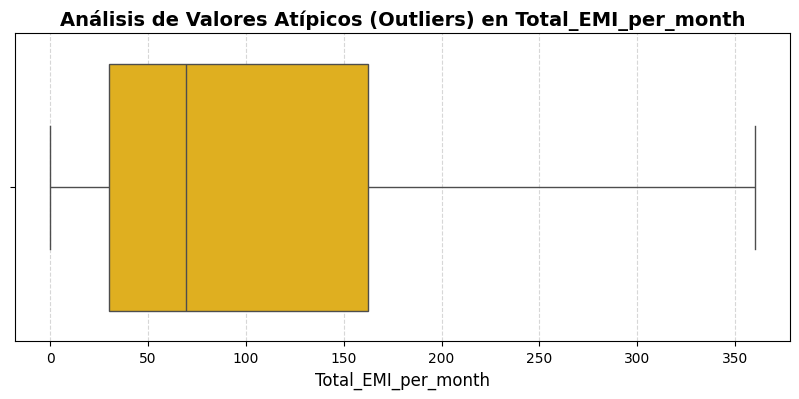

In [ ]:
# 2. Aplicamos el Capping basado en tu auditoría IQR (límite superior redondeado a 360.0)
# Acotamos el mínimo a 0.0 y el máximo a 360.0 manteniendo la escala flotante
data["Total_EMI_per_month"] = data["Total_EMI_per_month"].clip(lower=0.0, upper=360.0)


#Total_EMI_per_month
# Configuración del tamaño del lienzo
plt.figure(figsize=(10, 4))

# Renderizado del boxplot horizontal con un color ámbar hexadecimal válido
sns.boxplot(
    data=data,
    x="Total_EMI_per_month",
    color="#FFBF00",  # Código Hexadecimal para el color Ámbar
    flierprops={"markerfacecolor": "crimson", "markeredgecolor": "black", "marker": "o"}
)

# Títulos y etiquetas claras
plt.title("Análisis de Valores Atípicos (Outliers) en Total_EMI_per_month", fontsize=14, fontweight="bold")
plt.xlabel("Total_EMI_per_month", fontsize=12)

# Añadir cuadrícula sutil en el eje X
plt.grid(axis="x", linestyle="--", alpha=0.5)

# Mostrar el gráfico en pantalla
plt.show()


In [ ]:
# Amount_invested_monthly
# 1. Calcular los cuartiles y el Rango Intercuartílico (IQR)
q25 = data["Amount_invested_monthly"].quantile(0.25)
q75 = data["Amount_invested_monthly"].quantile(0.75)
iqr = q75 - q25

# 2. Calcular las fronteras de corte teóricas de la regla de Tukey
lower_bound = q25 - 1.5 * iqr
upper_bound = q75 + 1.5 * iqr

# 3. Contar cuántos registros caen fuera de los límites establecidos
outliers_bajos = (data["Amount_invested_monthly"] < lower_bound).sum()
outliers_altos = (data["Amount_invested_monthly"] > upper_bound).sum()
total_outliers = outliers_bajos + outliers_altos
total_registros = len(data)

# 4. Desplegar el reporte completo de auditoría en pantalla
print("📊 Reporte de Auditoría de Outliers (Método IQR) para Amount_invested_monthly")
print("-" * 65)
print(f"🔹 Cuartil 25% (Q1)     : {q25:,.2f}")
print(f"🔹 Cuartil 75% (Q3)     : {q75:,.2f}")
print(f"🔹 Rango Intercuartílico: {iqr:,.2f}")
print("-" * 65)
print(f"🚩 Umbral Límite Inferior (Menor a): {lower_bound:,.2f}")
print(f"🚩 Umbral Límite Superior (Mayor a): {upper_bound:,.2f}")
print("-" * 65)
print(f"❌ Datos que se borrarían en el extremo INFERIOR: {outliers_bajos} ({ (outliers_bajos / total_registros) * 100:.2f}%)")
print(f"❌ Datos que se borrarían en el extremo SUPERIOR: {outliers_altos} ({ (outliers_altos / total_registros) * 100:.2f}%)")
print(f"🚨 Total de registros en riesgo de eliminación   : {total_outliers} ({ (total_outliers / total_registros) * 100:.2f}%)")
print("-" * 65)

📊 Reporte de Auditoría de Outliers (Método IQR) para Amount_invested_monthly
-----------------------------------------------------------------
🔹 Cuartil 25% (Q1)     : 75.44
🔹 Cuartil 75% (Q3)     : 264.91
🔹 Rango Intercuartílico: 189.47
-----------------------------------------------------------------
🚩 Umbral Límite Inferior (Menor a): -208.76
🚩 Umbral Límite Superior (Mayor a): 549.11
-----------------------------------------------------------------
❌ Datos que se borrarían en el extremo INFERIOR: 0 (0.00%)
❌ Datos que se borrarían en el extremo SUPERIOR: 7224 (10.32%)
🚨 Total de registros en riesgo de eliminación   : 7224 (10.32%)
-----------------------------------------------------------------


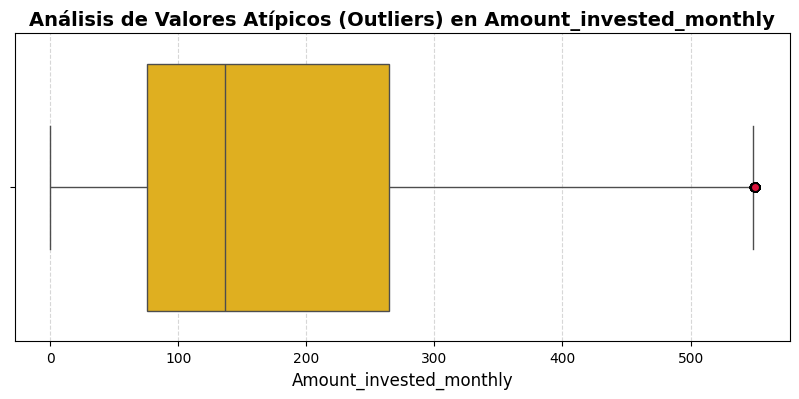

In [ ]:
# 2. ESTRATEGIA ÓPTIMA SUSTENTADA: Capping dual
# Acotamos el mínimo a 0.0 (no inversiones negativas) y el máximo a 550.0 (límite superior IQR redondeado)
data["Amount_invested_monthly"] = data["Amount_invested_monthly"].fillna(0.0).clip(lower=0.0, upper=550.0)

#Amount_invested_monthly
# Configuración del tamaño del lienzo
plt.figure(figsize=(10, 4))

# Renderizado del boxplot horizontal con un color ámbar hexadecimal válido
sns.boxplot(
    data=data,
    x="Amount_invested_monthly",
    color="#FFBF00",  # Código Hexadecimal para el color Ámbar
    flierprops={"markerfacecolor": "crimson", "markeredgecolor": "black", "marker": "o"}
)

# Títulos y etiquetas claras
plt.title("Análisis de Valores Atípicos (Outliers) en Amount_invested_monthly", fontsize=14, fontweight="bold")
plt.xlabel("Amount_invested_monthly", fontsize=12)

# Añadir cuadrícula sutil en el eje X
plt.grid(axis="x", linestyle="--", alpha=0.5)

# Mostrar el gráfico en pantalla
plt.show()


In [ ]:
# Payment_Behaviour
data["Payment_Behaviour"].unique()

array(['Low_spent_Large_value_payments',
       'High_spent_Large_value_payments',
       'High_spent_Small_value_payments',
       'Low_spent_Small_value_payments', '!@9#%8',
       'High_spent_Medium_value_payments',
       'Low_spent_Medium_value_payments'], dtype=object)

In [ ]:
# 1. LIMPIEZA INICIAL: Limpiamos espacios y convertimos la basura '!@9#%8' en 'Unknown'
data["Payment_Behaviour"] = data["Payment_Behaviour"].astype(str).str.strip()
data["Payment_Behaviour"] = data["Payment_Behaviour"].replace(["!@9#%8", "nan", "", "_______"], "Unknown")

# 2. DICCIONARIO DE MAPEO ORDINAL (Ordenado por Lógica de Riesgo Crediticio)
mapa_payment_behaviour = {
    "High_spent_Large_value_payments": 0,
    "Low_spent_Large_value_payments": 1,
    "High_spent_Medium_value_payments": 2,
    "Low_spent_Medium_value_payments": 3,
    "Unknown": 4,
    "High_spent_Small_value_payments": 5,
    "Low_spent_Small_value_payments": 6
}

# 3. TRANSFORMACIÓN A ENTERO PURO (Int64)
# Mapeamos los textos a números y aplicamos un relleno de seguridad a 'Unknown' (4) si quedara algún nulo flotante
data["Payment_Behaviour"] = data["Payment_Behaviour"].map(mapa_payment_behaviour).fillna(4).astype("Int64")

In [ ]:
# Monthly_Balance
# 1. Aseguramos que la columna sea flotante pura (tratando cualquier residuo de texto)
data["Monthly_Balance"] = pd.to_numeric(data["Monthly_Balance"], errors="coerce")

# 2. Calculamos el balance teórico usando tus columnas previamente depuradas
balance_teorico = data["Monthly_Inhand_Salary"] - (data["Total_EMI_per_month"] + data["Amount_invested_monthly"])

# 3. IMPUTACIÓN FINANCIERA: Rellenamos los vacíos donde la fórmula da el valor exacto
data["Monthly_Balance"] = data["Monthly_Balance"].fillna(balance_teorico)

# 4. RED DE SEGURIDAD EXTREMA: Si algún registro tuviera saldo negativo absurdo 
# por el comportamiento del dataset, limitamos el mínimo a 0 (el saldo libre no puede ser menor a cero de forma sostenida)
data["Monthly_Balance"] = data["Monthly_Balance"].clip(lower=0.0)

In [ ]:
# Monthly_Balance
# 1. Calcular los cuartiles y el Rango Intercuartílico (IQR)
q25 = data["Monthly_Balance"].quantile(0.25)
q75 = data["Monthly_Balance"].quantile(0.75)
iqr = q75 - q25

# 2. Calcular las fronteras de corte teóricas de la regla de Tukey
lower_bound = q25 - 1.5 * iqr
upper_bound = q75 + 1.5 * iqr

# 3. Contar cuántos registros caen fuera de los límites establecidos
outliers_bajos = (data["Monthly_Balance"] < lower_bound).sum()
outliers_altos = (data["Monthly_Balance"] > upper_bound).sum()
total_outliers = outliers_bajos + outliers_altos
total_registros = len(data)

# 4. Desplegar el reporte completo de auditoría en pantalla
print("📊 Reporte de Auditoría de Outliers (Método IQR) para Monthly_Balance")
print("-" * 65)
print(f"🔹 Cuartil 25% (Q1)     : {q25:,.2f}")
print(f"🔹 Cuartil 75% (Q3)     : {q75:,.2f}")
print(f"🔹 Rango Intercuartílico: {iqr:,.2f}")
print("-" * 65)
print(f"🚩 Umbral Límite Inferior (Menor a): {lower_bound:,.2f}")
print(f"🚩 Umbral Límite Superior (Mayor a): {upper_bound:,.2f}")
print("-" * 65)
print(f"❌ Datos que se borrarían en el extremo INFERIOR: {outliers_bajos} ({ (outliers_bajos / total_registros) * 100:.2f}%)")
print(f"❌ Datos que se borrarían en el extremo SUPERIOR: {outliers_altos} ({ (outliers_altos / total_registros) * 100:.2f}%)")
print(f"🚨 Total de registros en riesgo de eliminación   : {total_outliers} ({ (total_outliers / total_registros) * 100:.2f}%)")
print("-" * 65)

📊 Reporte de Auditoría de Outliers (Método IQR) para Monthly_Balance
-----------------------------------------------------------------
🔹 Cuartil 25% (Q1)     : 270.68
🔹 Cuartil 75% (Q3)     : 478.54
🔹 Rango Intercuartílico: 207.86
-----------------------------------------------------------------
🚩 Umbral Límite Inferior (Menor a): -41.11
🚩 Umbral Límite Superior (Mayor a): 790.33
-----------------------------------------------------------------
❌ Datos que se borrarían en el extremo INFERIOR: 0 (0.00%)
❌ Datos que se borrarían en el extremo SUPERIOR: 5737 (8.20%)
🚨 Total de registros en riesgo de eliminación   : 5737 (8.20%)
-----------------------------------------------------------------


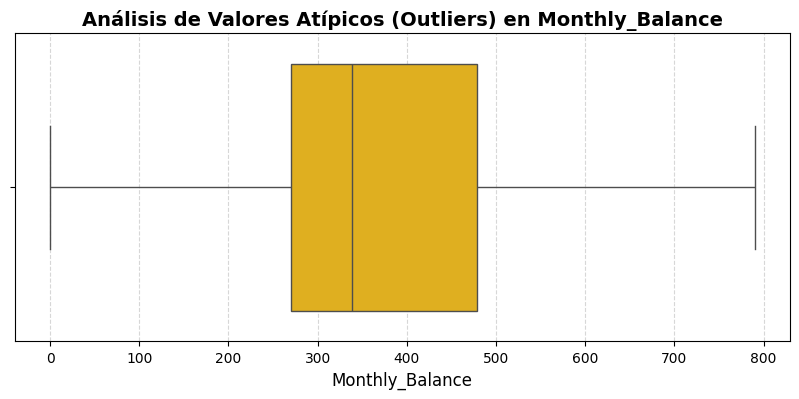

In [ ]:
# 1. Aseguramos formato numérico flotante puro (por si quedó algún residuo de texto)
data["Monthly_Balance"] = pd.to_numeric(data["Monthly_Balance"], errors="coerce")

# 2. Reconstrucción matemática para los 833 nulos
balance_teorico = data["Monthly_Inhand_Salary"] - (data["Total_EMI_per_month"] + data["Amount_invested_monthly"])

# 3. COMBINACIÓN ÓPTIMA: Imputación residual + Capping dual (0.0 a 790.0)
# Rellenamos los NaN con la fórmula y limitamos los extremos en una sola secuencia limpia
data["Monthly_Balance"] = data["Monthly_Balance"].fillna(balance_teorico).clip(lower=0.0, upper=790.0)


# Monthly_Balance
# Configuración del tamaño del lienzo
plt.figure(figsize=(10, 4))

# Renderizado del boxplot horizontal con un color ámbar hexadecimal válido
sns.boxplot(
    data=data,
    x="Monthly_Balance",
    color="#FFBF00",  # Código Hexadecimal para el color Ámbar
    flierprops={"markerfacecolor": "crimson", "markeredgecolor": "black", "marker": "o"}
)

# Títulos y etiquetas claras
plt.title("Análisis de Valores Atípicos (Outliers) en Monthly_Balance", fontsize=14, fontweight="bold")
plt.xlabel("Monthly_Balance", fontsize=12)

# Añadir cuadrícula sutil en el eje X
plt.grid(axis="x", linestyle="--", alpha=0.5)

# Mostrar el gráfico en pantalla
plt.show()

In [ ]:
# Credit_History_Age
# 1. Calcular los cuartiles y el Rango Intercuartílico (IQR)
q25 = data["Credit_History_Age"].quantile(0.25)
q75 = data["Credit_History_Age"].quantile(0.75)
iqr = q75 - q25

# 2. Calcular las fronteras de corte teóricas de la regla de Tukey
lower_bound = q25 - 1.5 * iqr
upper_bound = q75 + 1.5 * iqr

# 3. Contar cuántos registros caen fuera de los límites establecidos
outliers_bajos = (data["Credit_History_Age"] < lower_bound).sum()
outliers_altos = (data["Credit_History_Age"] > upper_bound).sum()
total_outliers = outliers_bajos + outliers_altos
total_registros = len(data)

# 4. Desplegar el reporte completo de auditoría en pantalla
print("📊 Reporte de Auditoría de Outliers (Método IQR) para Credit_History_Age")
print("-" * 65)
print(f"🔹 Cuartil 25% (Q1)     : {q25:,.2f}")
print(f"🔹 Cuartil 75% (Q3)     : {q75:,.2f}")
print(f"🔹 Rango Intercuartílico: {iqr:,.2f}")
print("-" * 65)
print(f"🚩 Umbral Límite Inferior (Menor a): {lower_bound:,.2f}")
print(f"🚩 Umbral Límite Superior (Mayor a): {upper_bound:,.2f}")
print("-" * 65)
print(f"❌ Datos que se borrarían en el extremo INFERIOR: {outliers_bajos} ({ (outliers_bajos / total_registros) * 100:.2f}%)")
print(f"❌ Datos que se borrarían en el extremo SUPERIOR: {outliers_altos} ({ (outliers_altos / total_registros) * 100:.2f}%)")
print(f"🚨 Total de registros en riesgo de eliminación   : {total_outliers} ({ (total_outliers / total_registros) * 100:.2f}%)")
print("-" * 65)

📊 Reporte de Auditoría de Outliers (Método IQR) para Credit_History_Age
-----------------------------------------------------------------
🔹 Cuartil 25% (Q1)     : 145.00
🔹 Cuartil 75% (Q3)     : 302.00
🔹 Rango Intercuartílico: 157.00
-----------------------------------------------------------------
🚩 Umbral Límite Inferior (Menor a): -90.50
🚩 Umbral Límite Superior (Mayor a): 537.50
-----------------------------------------------------------------
❌ Datos que se borrarían en el extremo INFERIOR: 0 (0.00%)
❌ Datos que se borrarían en el extremo SUPERIOR: 0 (0.00%)
🚨 Total de registros en riesgo de eliminación   : 0 (0.00%)
-----------------------------------------------------------------


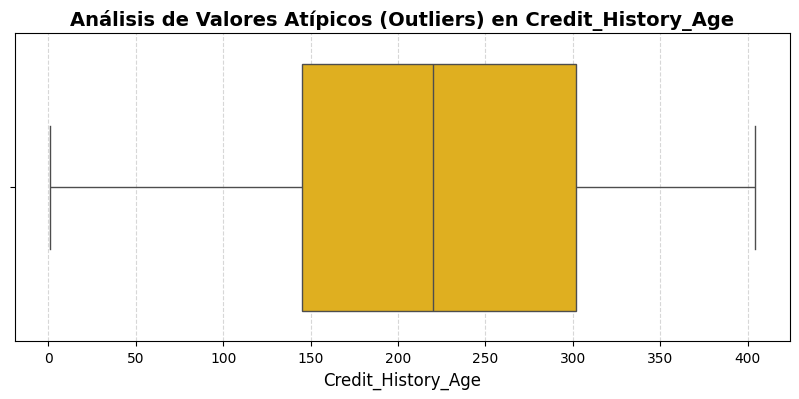

In [ ]:
# 1. Aseguramos formato numérico puro (por si quedó algún residuo en la conversión)
data["Credit_History_Age"] = pd.to_numeric(data["Credit_History_Age"], errors="coerce")

# ==========================================================
# 2. ESTRATEGIA ÓPTIMA FUSIONADA: Imputación + Blindaje Inferior
# ==========================================================
# Rellenamos los posibles NaN usando la mediana global del dataset
# e inmediatamente después forzamos que el límite mínimo sea 0 (no historiales negativos)
mediana_historial = data["Credit_History_Age"].median()

data["Credit_History_Age"] = data["Credit_History_Age"].fillna(mediana_historial).clip(lower=0.0)


# Credit_History_Age
# Configuración del tamaño del lienzo
plt.figure(figsize=(10, 4))

# Renderizado del boxplot horizontal con un color ámbar hexadecimal válido
sns.boxplot(
    data=data,
    x="Credit_History_Age",
    color="#FFBF00",  # Código Hexadecimal para el color Ámbar
    flierprops={"markerfacecolor": "crimson", "markeredgecolor": "black", "marker": "o"}
)

# Títulos y etiquetas claras
plt.title("Análisis de Valores Atípicos (Outliers) en Credit_History_Age", fontsize=14, fontweight="bold")
plt.xlabel("Credit_History_Age", fontsize=12)

# Añadir cuadrícula sutil en el eje X
plt.grid(axis="x", linestyle="--", alpha=0.5)

# Mostrar el grá

In [ ]:
data.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,69995,69995,0x1d653,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_ID,69995,12495,CUS_0x3d71,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Month,69995,8,May,8813,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Name,63011,10129,Stevex,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,69995.0,<NA>,<NA>,<NA>,33.476648,10.538446,18.0,24.0,33.0,42.0,60.0
SSN,69995,12496,#F%$D@*&8,3909,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Occupation,69995.0,NaN,NaN,NaN,6.982027,4.322227,0.0,3.0,7.0,11.0,14.0
Annual_Income,69995.0,NaN,NaN,NaN,51309.507727,38611.039996,7005.93,19532.06,37755.92,72817.02,152744.46
Monthly_Inhand_Salary,69995.0,NaN,NaN,NaN,4191.206494,3118.822955,303.645417,1633.28125,3117.101667,5981.988333,12505.05
Num_Bank_Accounts,69995.0,NaN,NaN,NaN,5.422702,2.630687,0.0,3.0,6.0,7.0,10.0


In [ ]:
# Check for null values in the 'data' DataFrame with the 'isnull().sum()'
# 1. Calculamos las métricas columna por columna
total_datos = len(data)  # Total de filas en el DataFrame
nulos = data.isnull().sum()
completos = data.count()
porcentaje_nulos = (nulos / total_datos) * 100

# 2. Construimos la tabla de resumen
tabla_diagnostico = pd.DataFrame({
    'Total Nulos': nulos,
    'Porcentaje Nulos (%)': porcentaje_nulos.round(2)  # Redondeado a 2 decimales
})

# 3. Mostramos la tabla completa
tabla_diagnostico

,Total Nulos,Porcentaje Nulos (%)
ID,0,0.00
Customer_ID,0,0.00
Month,0,0.00
Name,6984,9.98
Age,0,0.00
SSN,0,0.00
Occupation,0,0.00
Annual_Income,0,0.00
Monthly_Inhand_Salary,0,0.00
Num_Bank_Accounts,0,0.00


### **4. Label Isolation**
Aislamos las etiquetas de las características predictoras.

In [ ]:
# ==========================================================
# X_test_Kaggle: MISMO TRATAMIENTO QUE X_train_Kaggle (sin eliminar registros)
# Entrada: dataxtest (X_test_Kaggle.csv crudo)  ->  Salida: X_test
# Requiere haber ejecutado antes las celdas de entrenamiento
# (usa lista_ocupaciones_aux, data y datay ya definidos).
# ==========================================================
X_test = dataxtest.copy()
n_filas_original = len(X_test)

# ---------- Age ----------
X_test['Age'] = pd.to_numeric(X_test['Age'].astype(str).str.replace('_', '', regex=False), errors='coerce')
X_test.loc[(X_test['Age'] <= 0) | (X_test['Age'] >= 100), 'Age'] = np.nan
moda_edad = X_test.groupby('Customer_ID')['Age'].transform(lambda x: x.mode()[0] if not x.mode().empty else np.nan)
X_test['Age'] = X_test['Age'].fillna(moda_edad)
X_test['Age'] = X_test['Age'].fillna(X_test['Age'].median())
X_test['Age'] = X_test['Age'].round().astype('Int64').clip(lower=18, upper=60)

# ---------- Annual_Income / Monthly_Inhand_Salary ----------
X_test['Annual_Income'] = pd.to_numeric(X_test['Annual_Income'].astype(str).str.replace('_', '', regex=False), errors='coerce')
X_test['Monthly_Inhand_Salary'] = X_test['Monthly_Inhand_Salary'].fillna(X_test['Annual_Income'] / 12)
X_test['Annual_Income'] = X_test['Annual_Income'].clip(upper=152744.46)
X_test['Monthly_Inhand_Salary'] = X_test['Monthly_Inhand_Salary'].clip(upper=12505.05)

# ---------- Type_of_Loan -> Loan_Risk_Index y Total_Active_Loans ----------
X_test['Type_of_Loan'] = X_test['Type_of_Loan'].fillna('None')
X_test['Loan_Risk_Index'] = X_test['Type_of_Loan'].apply(calcular_indice_prestamo)
X_test['Total_Active_Loans'] = X_test['Type_of_Loan'].apply(
    lambda x: 0 if pd.isna(x) or str(x).strip() in ["", "nan", "None", "_______"]
    else len(str(x).replace(" and ", ", ").split(",")))

# ---------- Credit_Mix crudo (se usa como grupo de imputación, igual que en train) ----------
credit_mix_crudo = X_test['Credit_Mix'].copy()

# ---------- Num_of_Delayed_Payment ----------
X_test['Num_of_Delayed_Payment'] = X_test['Num_of_Delayed_Payment'].astype(str).str.replace('_', '', regex=False)
X_test['Num_of_Delayed_Payment'] = X_test['Num_of_Delayed_Payment'].replace('', np.nan)
modas_cliente = X_test.groupby('Customer_ID')['Num_of_Delayed_Payment'].transform(obtener_moda_segura)
X_test['Num_of_Delayed_Payment'] = X_test['Num_of_Delayed_Payment'].fillna(modas_cliente)
X_test['Num_of_Delayed_Payment'] = pd.to_numeric(X_test['Num_of_Delayed_Payment'].astype(str).str.extract(r'(\d+)')[0], errors='coerce')
med_pagos_cliente = X_test.groupby('Customer_ID')['Num_of_Delayed_Payment'].transform('median')
X_test['Num_of_Delayed_Payment'] = X_test['Num_of_Delayed_Payment'].fillna(med_pagos_cliente)
X_test['Num_of_Delayed_Payment'] = X_test['Num_of_Delayed_Payment'].fillna(X_test['Num_of_Delayed_Payment'].median())
X_test['Num_of_Delayed_Payment'] = X_test['Num_of_Delayed_Payment'].round().astype('Int64').clip(lower=0, upper=32)

# ---------- Num_Credit_Inquiries ----------
X_test['Num_Credit_Inquiries'] = pd.to_numeric(X_test['Num_Credit_Inquiries'].astype(str).str.extract(r'(\d+)')[0], errors='coerce')
X_test['Num_Credit_Inquiries'] = X_test['Num_Credit_Inquiries'].fillna(
    X_test.groupby(credit_mix_crudo)['Num_Credit_Inquiries'].transform('median'))
X_test['Num_Credit_Inquiries'] = X_test['Num_Credit_Inquiries'].fillna(X_test['Num_Credit_Inquiries'].median())
X_test['Num_Credit_Inquiries'] = X_test['Num_Credit_Inquiries'].round().astype('Int64').clip(lower=0, upper=18)

# ---------- Month -> Month_Code ----------
X_test['Month_Num'] = X_test['Month'].map(meses_12)
X_test['Month'] = pd.Categorical(X_test['Month'], categories=orden_meses, ordered=True)
X_test['Month_Code'] = X_test['Month'].cat.codes

# ---------- Credit_History_Age (meses; interpolación por cliente) ----------
X_test['Credit_History_Age'] = X_test['Credit_History_Age'].apply(texto_a_meses_puros)
orden_tmp = X_test.sort_values(by=['Customer_ID', 'Month_Num'])
hist = orden_tmp.groupby('Customer_ID')['Credit_History_Age'].transform(
    lambda x: x.interpolate(method='linear').ffill().bfill())
X_test['Credit_History_Age'] = hist.reindex(X_test.index)
X_test['Credit_History_Age'] = X_test['Credit_History_Age'].round().astype('Int64')
X_test = X_test.drop(columns=['Month_Num'])
X_test['Credit_History_Age'] = pd.to_numeric(X_test['Credit_History_Age'], errors='coerce')
X_test['Credit_History_Age'] = X_test['Credit_History_Age'].fillna(X_test['Credit_History_Age'].median()).clip(lower=0.0)

# ---------- Amount_invested_monthly ----------
X_test['Amount_invested_monthly'] = pd.to_numeric(
    X_test['Amount_invested_monthly'].astype(str).str.extract(r'([0-9.]+)')[0], errors='coerce')
X_test['Amount_invested_monthly'] = X_test['Amount_invested_monthly'].fillna(
    X_test.groupby('Customer_ID')['Amount_invested_monthly'].transform('median'))
X_test['Amount_invested_monthly'] = X_test['Amount_invested_monthly'].fillna(0.0).clip(lower=0.0, upper=550.0)

# ---------- Occupation (en train se eliminaban filas; aquí NO: se asigna 'Unknown') ----------
X_test['Occupation'] = X_test['Occupation'].astype(str).str.strip()
X_test.loc[X_test['Occupation'].isin(['_______', 'nan']), 'Occupation'] = np.nan
moda_ocup = X_test.groupby('Customer_ID')['Occupation'].transform(
    lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan)
X_test['Occupation'] = X_test['Occupation'].fillna(moda_ocup).fillna('Unknown')
X_test.loc[~X_test['Occupation'].isin(lista_ocupaciones_aux), 'Occupation'] = 'Unknown'
X_test['Occupation'] = pd.Categorical(X_test['Occupation'], categories=lista_ocupaciones_aux).codes

# ---------- Num_Bank_Accounts ----------
X_test['Num_Bank_Accounts'] = X_test['Num_Bank_Accounts'].clip(lower=0, upper=10)

# ---------- Num_Credit_Card ----------
X_test['Num_Credit_Card'] = X_test['Num_Credit_Card'].clip(lower=0)
X_test.loc[X_test['Num_Credit_Card'] > 10, 'Num_Credit_Card'] = np.nan
X_test['Num_Credit_Card'] = X_test['Num_Credit_Card'].fillna(
    X_test.groupby(credit_mix_crudo)['Num_Credit_Card'].transform('median'))
X_test['Num_Credit_Card'] = X_test['Num_Credit_Card'].fillna(X_test['Num_Credit_Card'].median())
X_test['Num_Credit_Card'] = X_test['Num_Credit_Card'].round().astype('Int64')

# ---------- Interest_Rate ----------
X_test['Interest_Rate'] = pd.to_numeric(X_test['Interest_Rate'], errors='coerce').clip(lower=0)
X_test.loc[X_test['Interest_Rate'] > 60, 'Interest_Rate'] = np.nan
X_test['Interest_Rate'] = X_test['Interest_Rate'].fillna(
    X_test.groupby(credit_mix_crudo)['Interest_Rate'].transform('median'))
X_test['Interest_Rate'] = X_test['Interest_Rate'].fillna(X_test['Interest_Rate'].median())

# ---------- Num_of_Loan ----------
X_test['Num_of_Loan'] = pd.to_numeric(X_test['Num_of_Loan'].astype(str).str.extract(r'(\d+)')[0], errors='coerce').clip(lower=0)
X_test.loc[X_test['Num_of_Loan'] > 12, 'Num_of_Loan'] = np.nan
X_test['Num_of_Loan'] = X_test['Num_of_Loan'].fillna(
    X_test.groupby(credit_mix_crudo)['Num_of_Loan'].transform('median'))
X_test['Num_of_Loan'] = X_test['Num_of_Loan'].fillna(X_test['Num_of_Loan'].median())
X_test['Num_of_Loan'] = X_test['Num_of_Loan'].round().astype('Int64')

# ---------- Delay_from_due_date ----------
X_test['Delay_from_due_date'] = pd.to_numeric(X_test['Delay_from_due_date'], errors='coerce').clip(lower=0)
X_test['Delay_from_due_date'] = X_test['Delay_from_due_date'].fillna(X_test['Delay_from_due_date'].median())

# ---------- Changed_Credit_Limit ----------
X_test['Changed_Credit_Limit'] = pd.to_numeric(
    X_test['Changed_Credit_Limit'].astype(str).str.extract(r'([0-9.]+)')[0], errors='coerce')
X_test['Changed_Credit_Limit'] = X_test['Changed_Credit_Limit'].fillna(0.0).clip(lower=0.0, upper=30.0)

# ---------- Credit_Mix (codificación) ----------
X_test['Credit_Mix'] = X_test['Credit_Mix'].astype(str).str.strip().replace(["_", "nan", "", "_______"], "Unknown")
X_test['Credit_Mix'] = X_test['Credit_Mix'].map(mapa_credit_mix).fillna(0).astype('int64')

# ---------- Outstanding_Debt ----------
X_test['Outstanding_Debt'] = pd.to_numeric(
    X_test['Outstanding_Debt'].astype(str).str.extract(r'([0-9.]+)')[0], errors='coerce')
X_test['Outstanding_Debt'] = X_test['Outstanding_Debt'].clip(lower=0.0, upper=4000.0)

# ---------- Payment_of_Min_Amount ----------
X_test['Payment_of_Min_Amount'] = X_test['Payment_of_Min_Amount'].astype(str).str.strip().replace(["nan", "", "_______"], "NM")
X_test['Payment_of_Min_Amount'] = X_test['Payment_of_Min_Amount'].map(mapa_pago_minimo).fillna(1).astype('Int64')

# ---------- Total_EMI_per_month ----------
X_test['Total_EMI_per_month'] = X_test['Total_EMI_per_month'].clip(lower=0.0, upper=360.0)

# ---------- Payment_Behaviour ----------
X_test['Payment_Behaviour'] = X_test['Payment_Behaviour'].astype(str).str.strip().replace(["!@9#%8", "nan", "", "_______"], "Unknown")
X_test['Payment_Behaviour'] = X_test['Payment_Behaviour'].map(mapa_payment_behaviour).fillna(4).astype('Int64')

# ---------- Monthly_Balance ----------
X_test['Monthly_Balance'] = pd.to_numeric(X_test['Monthly_Balance'], errors='coerce')
balance_teorico_test = X_test['Monthly_Inhand_Salary'] - (X_test['Total_EMI_per_month'] + X_test['Amount_invested_monthly'])
X_test['Monthly_Balance'] = X_test['Monthly_Balance'].fillna(balance_teorico_test).clip(lower=0.0, upper=790.0)

# ---------- Red de seguridad: nulos residuales -> mediana de train (no se elimina ninguna fila) ----------
for col in X_test.columns[X_test.isna().any()]:
    if col in data.columns and pd.api.types.is_numeric_dtype(data[col]):
        X_test[col] = X_test[col].fillna(data[col].median())

# ---------- Mismas columnas y orden que X_train (sin la variable objetivo) ----------
columnas_train = [c for c in data.columns if c not in datay.columns]
X_test = X_test[columnas_train]

# ---------- Verificación: no se perdió ningún registro ----------
assert len(X_test) == n_filas_original and X_test.index.equals(dataxtest.index), "Se alteraron registros del X_test"
print(f"✅ X_test listo: {X_test.shape} | registros originales: {n_filas_original} | nulos restantes: {int(X_test.isna().sum().sum())}")


✅ X_test listo: (30000, 30) | registros originales: 30000 | nulos restantes: 3001


In [ ]:
# ---------- X_train / y_train a partir del df limpio ----------
y_train = data['Credit_Score']
X_train = data.drop(columns=datay.columns)

# El RandomForest solo acepta columnas numéricas: se quitan las de texto/categoría
columnas_texto = X_train.select_dtypes(exclude='number').columns.tolist()
print("Columnas eliminadas (no numéricas):", columnas_texto)
X_train = X_train.drop(columns=columnas_texto)

# Nulos residuales -> mediana (por seguridad)
X_train = X_train.fillna(X_train.median())

assert len(X_train) == len(y_train), "X_train y y_train no tienen el mismo número de filas"
print(f"✅ X_train listo: {X_train.shape} | y_train: {y_train.shape}")

Columnas eliminadas (no numéricas): ['ID', 'Customer_ID', 'Month', 'Name', 'SSN', 'Type_of_Loan']
✅ X_train listo: (69995, 24) | y_train: (69995,)


### **5. Classifier (do not modify)**

In [ ]:
# Definimos el modelo RandomForestClassifier 
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap:

### **6. Predictions for Kaggle**

In [ ]:
# Mismas columnas y orden que X_train
X_test = X_test[X_train.columns]
y_pred = model.predict(X_test)

In [ ]:
# Aplicar misma limpieza a X_test antes de predecir

y_pred = model.predict(X_test)

### **7. Generate submission file**

In [90]:
# Importamos la base de datos 'sample_submission.csv' descargada de Kaggle
import pandas as pd

submission = pd.read_csv('sample_submission_credit.csv')

# Reemplazamos la columna 'class' en el archivo de submission con las predicciones y_pred
submission['class'] = y_pred

# Guardamos el archivo submission en formato CSV
submission.to_csv('submission.csv', index=False)

### **8. Rúbrica de Evaluación**

**Evaluación basada en posición en el leaderboard de Kaggle** 

**Pregrado:**

| Posición en el leaderboard | Calificación /10 | Calificación /6 |
|----------------------------|------------------|-----------------|
| 1.er lugar                 | 10               | 6               |
| 2.º lugar                 | 9.6              | 5.76             |
| 3.er lugar                | 9.2              | 5.52             |
| 4.º lugar                 | 8.8              | 5.28             |
| 5.º lugar                 | 8.4              | 5.04             |
| 6.º lugar                 | 8.0              | 4.8              |
| 7.º lugar                 | 7.8              | 4.68             |
| 8.º lugar                 | 7.6              | 4.56             |
| 9.º lugar                 | 7.4              | 4.44             |
| 10.º lugar                | 7.2              | 4.32             |
| 11.º lugar                | 7.0              | 4.25             |
| No entregó                | 0                | 0                |

**Postgrado**

| Posición en el leaderboard | Calificación /10 | 
|----------------------------|------------------|
| 1.er lugar                 | 10               |
| 2.º lugar                 | 9.5             | 
| 3.er lugar                | 9              |
| 4.º lugar                 | 8.5              | 
| 5.º lugar                 | 8              | 